# Aisle & Co. ETL pipeline demo
MADT 8102 Capstone, Chapter 6: Data Ingestion and ETL Design

Every cell below calls the pipeline in the `etl/` package, the same code that the command line
(`python -m etl run`) and the Airflow DAG `aisleco_daily_etl` run. The notebook does not recompute any
business rule itself. Two PostgreSQL databases are used:

* `aisleco_crm`: the source, OLTP v5 (OLTP v4 plus `UpdatedAt` on every table)
* `aisleco_dw`: the target, DW v7: a star schema of 4 dimensions and 3 facts, plus `stg` (9 staging
  tables), `etl` (7 control tables) and `mart` (11 views)

| Chapter 6 topic | How the pipeline does it | Section |
|---|---|---|
| Extract: full or incremental | Watermark on `UpdatedAt` per table; `--full-refresh` for a full load; deleted rows found from the key list | 4, 5 |
| Extract: parallel, light on the source | One worker per table, all reading one shared snapshot (`pg_export_snapshot`); bulk `COPY`; `UpdatedAt` indexes | 1, 4 |
| Transform: cleaning, joining, aggregation | SQL files in `sql/transform/`: response time from chat messages, staff hours spread over weeks, funnel flags | 2, 4 |
| Transform: personal data | Customer, contact and chat-account tables are never extracted; `CustomerID` is not read (PDPA) | 1, 4 |
| Transform: validation, lineage, metadata | 27 data-quality rules stored in `etl.DqRule`; `_RunID` on every staging row; a manifest per run | 3, 7 |
| Load: bulk, incremental | `COPY` into landing tables; facts merged, writing only the rows whose values changed | 4, 11 |
| Load: integrity | Foreign and unique keys in DW v7; reconciliation after every load | 1, 12 |
| Modular design | 11 steps, one file or function each; the same steps in the CLI and in Airflow | 2 |
| Error handling | Connection retry with backoff, step log `etl.StepRun`, dead-letter queue `etl.RejectedRow`, alerts `etl.Alert` | 7 to 10 |
| Recovery | Resume skips the steps that succeeded; running again changes nothing | 9, 11 |
| Capacity | Batch cap of 100,000 changes per run; the rest waits in the backlog queue in the CRM | 13 |
| Testing | 33 automated tests, a 28,638-value source-to-target check, a stress test against the 2-minute target | 12 to 14 |
| Business problems | Problem 1 (seasonal demand and capacity): staffing decisions run by run. Problem 2 (high inquiry, low conversion): inquiries followed run by run. The KPIs of both on a business year | 5, 6, 12 |
| ETL or ELT | Python extracts and lands the data; the transformations run as SQL inside the warehouse, so strictly ELT | 1 |

In [1]:
import os, sys, json, subprocess, logging, time
T0 = time.perf_counter()     # the whole notebook is timed against the 2-minute target in section 13
from dataclasses import replace
from datetime import date
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

ROOT = Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
from etl import pipeline, db
from etl.config import Config
from etl.__main__ import init_dw
from crm import create_crm, crm_exec
import load_walkthrough

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(message)s")   # show alerts only
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)

cfg = Config()          # aisleco_crm -> aisleco_dw, landing files in data/landing
# Everything in this notebook happens within seconds, so the production overlap of 5 minutes
# would re-read every row each time. With 0 the effect of the watermark is visible.
demo = replace(cfg, overlap_seconds=0)

def dw(sql, params=None, c=cfg):
    with db.connect(c.dw_dsn, c) as conn:
        return pd.DataFrame(conn.execute(sql, params).fetchall())

def crm(sql, params=None, c=cfg):
    with db.connect(c.crm_dsn, c) as conn:
        return pd.DataFrame(conn.execute(sql, params).fetchall())

def run_log(run_id, c=cfg):
    df = dw('''SELECT "Step", "Attempt", "Status", "DurationSec" AS sec, "RowsIn", "RowsOut", "Metrics", left("Error", 80) AS error
               FROM etl."StepRun" WHERE "RunID"=%s ORDER BY "StepRunID"''', (run_id,), c)
    keep = ("inserted", "updated", "unchanged", "deleted", "frozen_changed")
    df["changes"] = df.pop("Metrics").map(lambda m: {k: v for k, v in (m or {}).items() if k in keep and v} or "")
    return df

def staged(run_id, c=cfg):
    m = dw('''SELECT "Metrics" FROM etl."StepRun" WHERE "RunID"=%s AND "Step"='stage' AND "Status"='success' ''', (run_id,), c)
    t = pd.DataFrame(m.iloc[0, 0]["tables"]).T
    return t[["extracted", "rejected", "inserted", "updated", "unchanged", "deleted"]]

def week(start="2027-02-08", c=cfg):
    return dw('''SELECT split_part(employee,' ',1) AS employee, role, "TotalAssignedHours" AS hours, "StandardWeeklyHours" AS std_hours,
                        round("UtilizationRate"*100) AS utilization_pct, "OvertimeHours" AS overtime, "ActiveEvents" AS events
                 FROM mart.v_weekly_workload WHERE week_start=%s AND "TotalAssignedHours" > 0 ORDER BY 1''', (start,), c)
print("CRM:", cfg.crm_dsn, "| DW:", cfg.dw_dsn, "| landing:", cfg.landing_dir.relative_to(ROOT))

CRM: dbname=aisleco_crm | DW: dbname=aisleco_dw | landing: data/landing


## 1. Architecture and schema

The pipeline follows the five data zones of Section 5.5. The CRM is the Collection zone. Extract copies
the changed rows into landing files (Bronze). The stage step checks them and merges them into `stg`
(Silver). SQL builds the dimensions and facts (Gold), and the `mart` views are what the meetings and
reports read (Consumption). The `etl` schema records every run, step, watermark, quality check, rejected
row and alert.

Source and target are separate databases, and nothing is calculated in the CRM. The transformations run
as SQL inside the warehouse after loading, so strictly the design is ELT (Section 6.1). Two queues hold
data that is not loaded yet: the backlog queue (changes beyond the batch cap wait in the CRM) and the
dead-letter queue (rows that failed a rule wait in `etl.RejectedRow`).

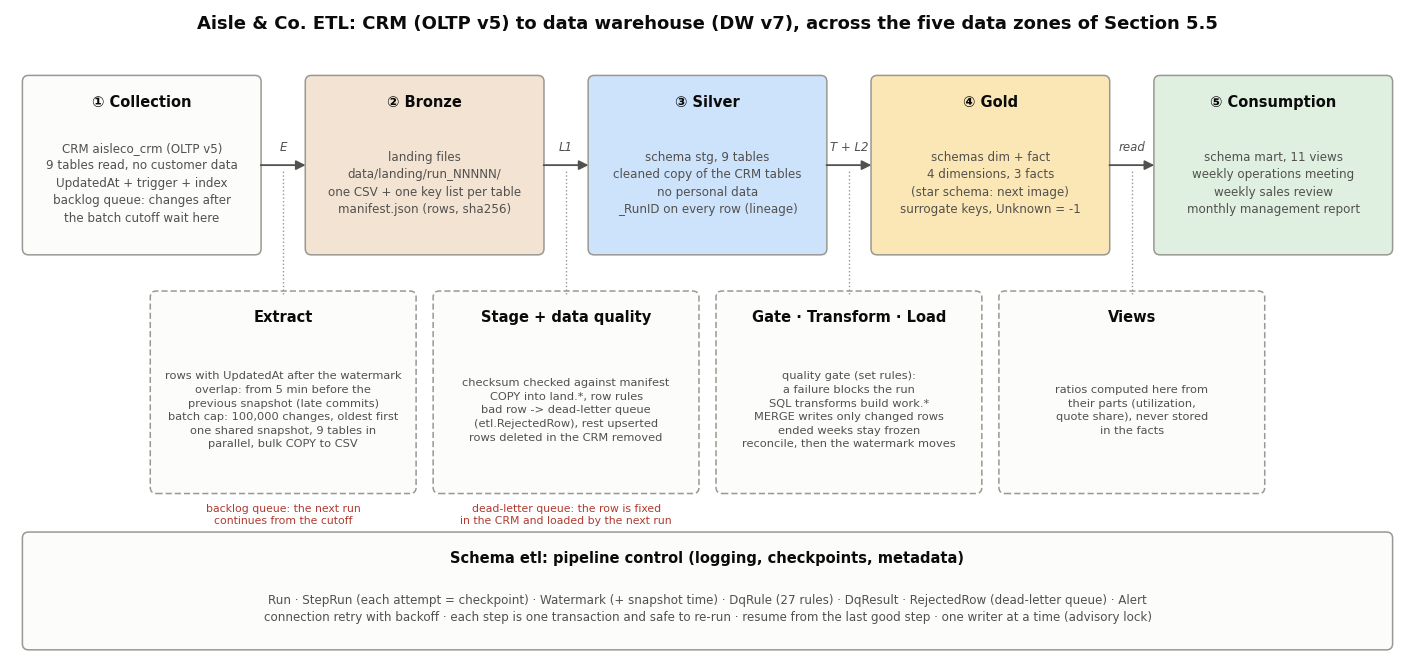

In [2]:
INK, INK2, EDGE, BLUE, GOLD = "#0b0b0b", "#52514e", "#9a9893", "#cde2fb", "#fbe7b5"
BRONZE, GREEN, RED = "#f3e3d3", "#dff0e1", "#b03a2e"
fig, ax = plt.subplots(figsize=(18, 8.4)); ax.set_xlim(0, 18); ax.set_ylim(0, 8.4); ax.axis("off")
def box(x, y, w, h, title, body, fc="#fcfcfb", ls="-", size=8.6):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.08", lw=1.1, ec=EDGE, fc=fc, ls=ls))
    ax.text(x + w / 2, y + h - 0.2, title, ha="center", va="top", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(x + w / 2, y + (h - 0.45) / 2, body, ha="center", va="center", fontsize=size, color=INK2, linespacing=1.45)
def arrow(x1, y1, x2, y2, label="", color=INK2, ls="-"):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=14, lw=1.3, color=color, ls=ls))
    if label:
        ax.text((x1 + x2) / 2, y1 + 0.2, label, ha="center", fontsize=8.5, color=INK2, style="italic")

ZW, ZY, ZH = 3.0, 5.25, 2.25                      # zone boxes (data at rest)
zx = [0.2 + i * 3.65 for i in range(5)]
box(zx[0], ZY, ZW, ZH, "① Collection", "CRM aisleco_crm (OLTP v5)\n9 tables read, no customer data\nUpdatedAt + trigger + index\nbacklog queue: changes after\nthe batch cutoff wait here")
box(zx[1], ZY, ZW, ZH, "② Bronze", "landing files\ndata/landing/run_NNNNN/\none CSV + one key list per table\nmanifest.json (rows, sha256)", fc=BRONZE)
box(zx[2], ZY, ZW, ZH, "③ Silver", "schema stg, 9 tables\ncleaned copy of the CRM tables\nno personal data\n_RunID on every row (lineage)", fc=BLUE)
box(zx[3], ZY, ZW, ZH, "④ Gold", "schemas dim + fact\n4 dimensions, 3 facts\n(star schema: next image)\nsurrogate keys, Unknown = -1", fc=GOLD)
box(zx[4], ZY, ZW, ZH, "⑤ Consumption", "schema mart, 11 views\nweekly operations meeting\nweekly sales review\nmonthly management report", fc=GREEN)
for i, lab in enumerate(["E", "L1", "T + L2", "read"]):
    arrow(zx[i] + ZW, ZY + ZH / 2, zx[i + 1], ZY + ZH / 2, lab)

PW, PY, PH = 3.35, 2.15, 2.55                     # process boxes (what each step does)
steps = [
    ("Extract", "rows with UpdatedAt after the watermark\noverlap: from 5 min before the\nprevious snapshot (late commits)\nbatch cap: 100,000 changes, oldest first\none shared snapshot, 9 tables in\nparallel, bulk COPY to CSV"),
    ("Stage + data quality", "checksum checked against manifest\nCOPY into land.*, row rules\nbad row -> dead-letter queue\n(etl.RejectedRow), rest upserted\nrows deleted in the CRM removed"),
    ("Gate · Transform · Load", "quality gate (set rules):\na failure blocks the run\nSQL transforms build work.*\nMERGE writes only changed rows\nended weeks stay frozen\nreconcile, then the watermark moves"),
    ("Views", "ratios computed here from\ntheir parts (utilization,\nquote share), never stored\nin the facts"),
]
for i, (t, b) in enumerate(steps):
    cx = zx[i] + ZW + 0.325
    box(cx - PW / 2, PY, PW, PH, t, b, ls=(0, (4, 2)), size=8.2)
    ax.plot([cx, cx], [PY + PH, ZY + ZH / 2 - 0.08], ls=":", color=EDGE, lw=1)
ax.text(zx[1] + ZW + 0.325, PY - 0.17, "dead-letter queue: the row is fixed\nin the CRM and loaded by the next run", ha="center", va="top", fontsize=7.8, color=RED)
ax.text(zx[0] + ZW + 0.325, PY - 0.17, "backlog queue: the next run\ncontinues from the cutoff", ha="center", va="top", fontsize=7.8, color=RED)

box(0.2, 0.12, 17.6, 1.45, "Schema etl: pipeline control (logging, checkpoints, metadata)",
    "Run · StepRun (each attempt = checkpoint) · Watermark (+ snapshot time) · DqRule (27 rules) · DqResult · RejectedRow (dead-letter queue) · Alert\n"
    "connection retry with backoff · each step is one transaction and safe to re-run · resume from the last good step · one writer at a time (advisory lock)")
ax.text(9.0, 8.15, "Aisle & Co. ETL: CRM (OLTP v5) to data warehouse (DW v7), across the five data zones of Section 5.5",
        ha="center", fontsize=13, fontweight="bold", color=INK)
plt.savefig(ROOT / "docs" / "etl_architecture.png", dpi=150, bbox_inches="tight"); plt.show()

The Gold zone, drawn from the schema file `sql/WeddingOrganizer_DW_v7_dbdiagram.sql`, so the picture always matches
the DDL. FactInquiry uses DimDate in four roles. Ratios are not stored: utilization and quote share are
computed in the `mart` views from the columns shown here.

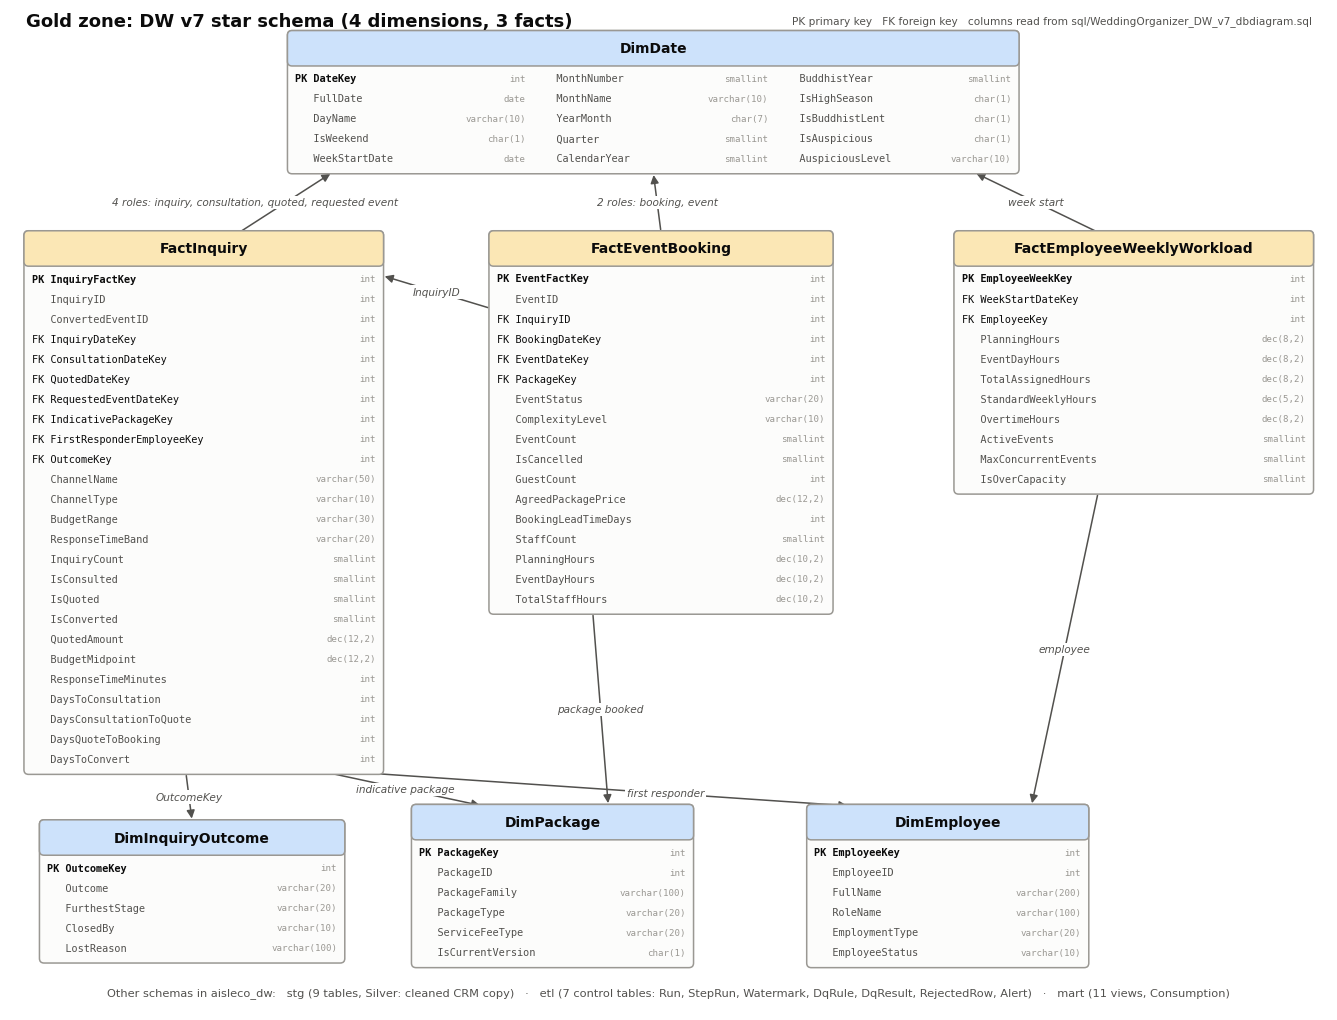

In [3]:
import re
ddl = (ROOT / "sql" / "WeddingOrganizer_DW_v7_dbdiagram.sql").read_text()
tables = {}
for schema, name, body in re.findall(r'CREATE TABLE "(dim|fact)"\."(\w+)" \((.*?)\n\);', ddl, re.S):
    cols = []
    for line in body.strip().splitlines():
        m = re.match(r'\s*"(\w+)" (\w+(?:\(\d+(?:,\d+)?\))?)', line)
        if m:
            cols.append([m.group(1), m.group(2).lower().replace("decimal", "dec"), "PK" if "PRIMARY KEY" in line else ""])
    tables[name] = cols
fks = re.findall(r'ALTER TABLE "fact"\."(\w+)" ADD FOREIGN KEY \("(\w+)"\) REFERENCES "\w+"\."(\w+)"', ddl)
for t, c, _ in fks:
    for col in tables[t]:
        if col[0] == c:
            col[2] = "FK"
views = re.findall(r"CREATE OR REPLACE VIEW mart\.(\w+)", (ROOT / "sql" / "dw_v7_mart_views.sql").read_text())
others = {s: re.findall(rf'CREATE TABLE "{s}"\."(\w+)"', ddl) for s in ("stg", "etl")}

RH = 0.26                                    # row height
fig, ax = plt.subplots(figsize=(17, 13)); ax.set_xlim(0, 17); ax.set_ylim(-0.5, 12.5); ax.axis("off")
geo = {}
def table(name, x, y_top, w, ncol=1, fc="#fcfcfb"):
    cols = tables[name]
    rows = -(-len(cols) // ncol)
    h = 0.42 + rows * RH + 0.1
    ax.add_patch(FancyBboxPatch((x, y_top - h), w, h, boxstyle="round,pad=0.02,rounding_size=0.06", fc=fc, ec=EDGE, lw=1.1, zorder=3))
    ax.add_patch(FancyBboxPatch((x, y_top - 0.42), w, 0.42, boxstyle="round,pad=0.02,rounding_size=0.06", fc=GOLD if name.startswith("Fact") else BLUE, ec=EDGE, lw=1.1, zorder=3))
    ax.text(x + w / 2, y_top - 0.21, name, ha="center", va="center", fontsize=10, fontweight="bold", color=INK, zorder=4)
    cw = w / ncol
    for i, (c, ty, k) in enumerate(cols):
        cx, cy = x + (i // rows) * cw + 0.08, y_top - 0.42 - 0.05 - (i % rows + 0.5) * RH
        ax.text(cx, cy, f"{k:<2} {c}", ha="left", va="center", fontsize=7.4, family="monospace", zorder=4,
                color=INK if k else INK2, fontweight="bold" if k == "PK" else "normal")
        ax.text(cx + cw - 0.16, cy, ty, ha="right", va="center", fontsize=6.6, family="monospace", color=EDGE, zorder=4)
    geo[name] = (x, y_top - h, w, h)
def edge(a, b, label="", side_a="top", side_b="bottom", fa=0.5, fb=0.5, lx=0, ly=0, at=0.5):
    def pt(n, side, f):
        x, y, w, h = geo[n]
        return {"top": (x + w * f, y + h), "bottom": (x + w * f, y), "left": (x, y + h * f), "right": (x + w, y + h * f)}[side]
    p, q = pt(a, side_a, fa), pt(b, side_b, fb)
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=12, lw=1.1, color=INK2, zorder=2))
    if label:
        ax.text(p[0] + (q[0] - p[0]) * at + lx, p[1] + (q[1] - p[1]) * at + ly, label, ha="center", va="center", fontsize=7.6, color=INK2,
                style="italic", zorder=5, bbox=dict(fc="white", ec="none", pad=1.2))

table("DimDate", 3.6, 12.2, 9.4, ncol=3)
table("FactInquiry", 0.2, 9.6, 4.6)
table("FactEventBooking", 6.2, 9.6, 4.4)
table("FactEmployeeWeeklyWorkload", 12.2, 9.6, 4.6)
table("DimInquiryOutcome", 0.4, 1.95, 3.9)
table("DimPackage", 5.2, 2.15, 3.6)
table("DimEmployee", 10.3, 2.15, 3.6)
roles = {t: [re.sub(r"(?<=[a-z])(?=[A-Z])", " ", c.removesuffix("DateKey")).lower() for tt, c, d in fks if tt == t and d == "DimDate"] for t in tables}
edge("FactInquiry", "DimDate", f"{len(roles['FactInquiry'])} roles: " + ", ".join(roles["FactInquiry"]), fa=0.6, fb=0.06, lx=-0.4)
edge("FactEventBooking", "DimDate", f"{len(roles['FactEventBooking'])} roles: " + ", ".join(roles["FactEventBooking"]), fb=0.5)
edge("FactEmployeeWeeklyWorkload", "DimDate", "week start", fa=0.4, fb=0.94)
edge("FactEventBooking", "FactInquiry", "InquiryID", side_a="left", side_b="right", fa=0.8, fb=0.92)
edge("FactInquiry", "DimInquiryOutcome", "OutcomeKey", side_a="bottom", side_b="top", fa=0.45)
edge("FactInquiry", "DimPackage", "indicative package", side_a="bottom", side_b="top", fa=0.85, fb=0.25)
edge("FactEventBooking", "DimPackage", "package booked", side_a="bottom", side_b="top", fa=0.3, fb=0.7)
edge("FactInquiry", "DimEmployee", "first responder", side_a="bottom", side_b="top", fa=0.95, fb=0.15, at=0.62)
edge("FactEmployeeWeeklyWorkload", "DimEmployee", "employee", side_a="bottom", side_b="top", fa=0.4, fb=0.8)
strip = (f"Other schemas in aisleco_dw:   stg ({len(others['stg'])} tables, Silver: cleaned CRM copy)   ·   "
         f"etl ({len(others['etl'])} control tables: {', '.join(others['etl'])})   ·   mart ({len(views)} views, Consumption)")
ax.text(8.5, -0.35, strip, ha="center", va="bottom", fontsize=8.2, color=INK2)
ax.text(0.2, 12.35, "Gold zone: DW v7 star schema (4 dimensions, 3 facts)", ha="left", va="center", fontsize=13, fontweight="bold", color=INK)
ax.text(16.8, 12.35, "PK primary key   FK foreign key   columns read from sql/WeddingOrganizer_DW_v7_dbdiagram.sql",
        ha="right", va="center", fontsize=7.6, color=INK2)
plt.savefig(ROOT / "docs" / "dw_schema.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Steps

Each step does one job and runs in its own transaction, so a failed step leaves nothing half-written and
can be run again. The arrows are the dependencies Airflow uses. The three dimension steps run in parallel
(DimInquiryOutcome is loaded inside `fact_inquiry`), and the weekly workload fact does not wait for the
inquiry facts.

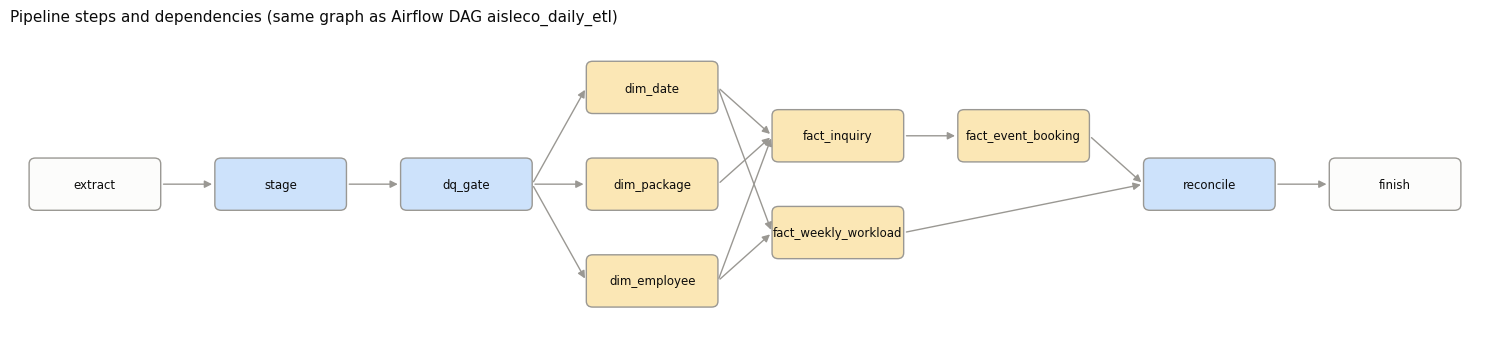

In [4]:
deps = pipeline.DEPENDS
layer = {}
def depth(n): return layer.setdefault(n, 0 if not deps[n] else 1 + max(depth(p) for p in deps[n]))
for n in deps: depth(n)
cols = {}
for n, d in layer.items(): cols.setdefault(d, []).append(n)
pos = {n: (d * 1.75, -i * 1.0 + (len(ns) - 1) / 2) for d, ns in cols.items() for i, n in enumerate(ns)}
pos["fact_event_booking"] = (pos["fact_event_booking"][0], pos["fact_inquiry"][1])   # keep the weekly edge clear
fig, ax = plt.subplots(figsize=(15, 3.6)); ax.axis("off")
for n, ups in deps.items():
    for u in ups:
        ax.add_patch(FancyArrowPatch((pos[u][0] + 0.62, pos[u][1]), (pos[n][0] - 0.62, pos[n][1]), arrowstyle="-|>", mutation_scale=11, color=EDGE, lw=1))
for n, (x, y) in pos.items():
    fc = "#fbe7b5" if n.startswith(("dim", "fact")) else "#cde2fb" if n in ("stage", "dq_gate", "reconcile") else "#fcfcfb"
    ax.add_patch(FancyBboxPatch((x - 0.6, y - 0.25), 1.2, 0.5, boxstyle="round,pad=0.02,rounding_size=0.06", fc=fc, ec=EDGE))
    ax.text(x, y, n, ha="center", va="center", fontsize=8.5, color=INK)
ax.set_xlim(-0.8, max(p[0] for p in pos.values()) + 0.8); ax.set_ylim(-1.6, 1.6)
ax.set_title("Pipeline steps and dependencies (same graph as Airflow DAG aisleco_daily_etl)", loc="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(ROOT / "docs" / "etl_dag.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. Start from empty

Create the CRM and the warehouse. The 27 data-quality rules are stored in `etl.DqRule` when the
warehouse is created.

In [5]:
create_crm(cfg)
init_dw(cfg, drop=True)
rules = dw('SELECT "RuleName", "TableName", "Kind", "Severity", "Description" FROM etl."DqRule" ORDER BY "RuleID"')
print(rules.groupby(["Kind", "Severity"]).size().rename("rules").to_string()); rules

warehouse aisleco_dw created (DW v7) with 27 data-quality rules
Kind   Severity
recon  block        6
       warn         1
row    reject      14
       warn         2
set    block        3
       warn         1


,RuleName,TableName,Kind,Severity,Description
0,chat_staff_without_employee,ChatMessage,row,reject,A staff message must name the staff member (needed for first respo...
1,chat_invalid_values,ChatMessage,row,reject,"Direction In/Out, SenderType Customer/Staff/Bot and SentAt are req..."
2,chat_orphan_inquiry,ChatMessage,row,reject,Message points to an inquiry that is not in staging (e.g. the inqu...
3,inquiry_missing_date,Inquiry,row,reject,InquiryDate is required (every conversion KPI is grouped by it)
4,inquiry_invalid_status,Inquiry,row,reject,Status must be New / Contacted / Quoted / Converted / Lost
5,inquiry_negative_quote,Inquiry,row,reject,QuotedAmount cannot be negative
6,inquiry_orphan_channel,Inquiry,row,reject,Channel not in staging
7,event_missing_dates,Event,row,reject,EventDate and CreatedDate (booking date) are required to place the...
8,event_invalid_values,Event,row,reject,GuestCount and AgreedPackagePrice cannot be negative
9,event_orphan_inquiry,Event,row,reject,Event points to an inquiry that is not in staging


## 4. First load: Appendix B, parts 0 to 3

The CRM receives the reference data and three couples: Ploy & Ton (met at a wedding fair, booked),
Nok & Bank (Facebook, went silent) and Mint & Jay (asked for 13 Feb 2027). The first run is dated
23 Nov 2026. There is no watermark yet, so it extracts every row.

In [6]:
parts = list(load_walkthrough.parts())
for label, title, body in parts[:4]:
    crm_exec(body, cfg); print("CRM <-", label, title)
run1 = pipeline.run(demo, date(2026, 11, 23))
snap = {"Run 1 · 23 Nov": week()}
print(f"\nrun {run1}: succeeded"); run_log(run1)

CRM <- PART 0 reference data already in the CRM
CRM <- PART 1 Ploy & Ton (fair -> booked)
CRM <- PART 2 Nok & Bank (Facebook, night, goes silent)
CRM <- PART 3 Mint & Jay ask for 13 Feb 2027 (capacity decision)

run 1: succeeded


,Step,Attempt,Status,sec,RowsIn,RowsOut,error,changes
0,extract,1,success,0.020,58.0,58.0,None,
1,stage,1,success,0.024,58.0,58.0,None,
2,dq_gate,1,success,0.004,NaN,NaN,None,
3,dim_date,1,success,0.014,NaN,1461.0,None,{'inserted': 1461}
4,dim_package,1,success,0.003,NaN,3.0,None,{'inserted': 3}
5,dim_employee,1,success,0.003,NaN,5.0,None,{'inserted': 5}
6,fact_inquiry,1,success,0.011,3.0,3.0,None,{'inserted': 3}
7,fact_event_booking,1,success,0.008,5.0,5.0,None,{'inserted': 5}
8,fact_weekly_workload,1,success,0.010,230.0,230.0,None,{'inserted': 230}
9,reconcile,1,success,0.014,NaN,NaN,None,


In [7]:
print("What was extracted and how it went into staging (run %d):" % run1); staged(run1)

What was extracted and how it went into staging (run 1):


,extracted,rejected,inserted,updated,unchanged,deleted
Event,5,0,5,0,0,0
Inquiry,3,0,3,0,0,0
Package,3,0,3,0,0,0
Employee,5,0,5,0,0,0
ChatMessage,11,0,11,0,0,0
EmployeeRole,5,0,5,0,0,0
AuspiciousDate,4,0,4,0,0,0
MarketingChannel,8,0,8,0,0,0
EventEmployeeAssignment,14,0,14,0,0,0


In [8]:
folder = cfg.landing_dir / f"run_{run1:05d}"
print("Landing folder (Bronze):", folder.relative_to(ROOT))
for f in sorted(folder.iterdir()): print(f"   {f.name:<36} {f.stat().st_size:>7,} bytes")
m = json.loads((folder / "manifest.json").read_text())
pd.DataFrame(m["tables"]).T[["since", "rows", "keys", "max_updated_at", "sha256"]].assign(sha256=lambda x: x.sha256.str[:12] + "…")

Landing folder (Bronze): data/landing/run_00001
   AuspiciousDate.csv                       307 bytes
   AuspiciousDate_keys.csv                   41 bytes
   ChatMessage.csv                          770 bytes
   ChatMessage_keys.csv                      68 bytes
   Employee.csv                             488 bytes
   EmployeeRole.csv                         232 bytes
   EmployeeRole_keys.csv                     35 bytes
   Employee_keys.csv                         39 bytes
   Event.csv                                581 bytes
   EventEmployeeAssignment.csv            1,226 bytes
   EventEmployeeAssignment_keys.csv          95 bytes
   Event_keys.csv                            44 bytes
   Inquiry.csv                              676 bytes
   Inquiry_keys.csv                          30 bytes
   MarketingChannel.csv                     407 bytes
   MarketingChannel_keys.csv                 50 bytes
   Package.csv                              256 bytes
   Package_keys.csv               

,since,rows,keys,max_updated_at,sha256
MarketingChannel,None,8,8,2026-11-07T14:31:43.412774,024f5224c4d1…
Package,None,3,3,2026-11-07T14:31:43.412774,dd9b53f2bcf6…
EmployeeRole,None,5,5,2026-11-07T14:31:43.412774,d31b92102e30…
Employee,None,5,5,2026-11-07T14:31:43.412774,bb7578473c35…
AuspiciousDate,None,4,4,2026-11-07T14:31:43.412774,3417c3c55628…
Inquiry,None,3,3,2026-11-07T14:31:43.425185,99f770243a1a…
ChatMessage,None,11,11,2026-11-07T14:31:43.425185,a497cb88101d…
Event,None,5,5,2026-11-07T14:31:43.417224,7f2966933966…
EventEmployeeAssignment,None,14,14,2026-11-07T14:31:43.417224,d6fb0c6423c7…


### Source to target for one inquiry (Ploy & Ton, inquiry 1)

The same inquiry in each zone: the CRM rows, the staging row (`CustomerID` is not extracted) and the
warehouse row. The last two lines recompute two rules by hand and compare them with the warehouse.

In [9]:
print("SOURCE  CRM transaction.Inquiry"); display(crm('''SELECT "InquiryID","CustomerID","ChannelID","InquiryDate","BudgetRange",
       "ConsultationDate","QuotedDate","QuotedAmount","Status","ClosedBy" FROM transaction."Inquiry" WHERE "InquiryID"=1'''))
chat = crm('''SELECT "SentAt","Direction","SenderType","EmployeeID" FROM transaction."ChatMessage" WHERE "InquiryID"=1 ORDER BY 1''')
print("SOURCE  CRM transaction.ChatMessage"); display(chat)
print("SILVER  stg.Inquiry (CustomerID is not extracted: PDPA)"); display(dw('''SELECT "InquiryID","ChannelID","InquiryDate","BudgetRange",
       "QuotedAmount","Status","_RunID" FROM stg."Inquiry" WHERE "InquiryID"=1'''))
print("GOLD    mart.v_inquiry (fact + DimInquiryOutcome)")
f = dw('''SELECT "ChannelName","ResponseTimeMinutes","ResponseTimeBand","FirstResponderEmployeeKey","FurthestStage","Outcome",
                 "BudgetMidpoint","QuotedAmount","QuoteShareOfBudget","DaysToConsultation","IsConverted"
          FROM mart.v_inquiry WHERE "InquiryID"=1''')
display(f)
first_in = chat.query("SenderType == 'Customer'").SentAt.min()
first_staff = chat.query("SenderType == 'Staff' and SentAt >= @first_in").SentAt.min()
print(f"rule check  response time = first staff reply - first customer message (bot ignored) = "
      f"{(first_staff - first_in).total_seconds() // 60:.0f} min  -> fact {f.ResponseTimeMinutes[0]}")
print(f"rule check  quote share = QuotedAmount / BudgetMidpoint = {float(f.QuotedAmount[0]):,.0f} / {float(f.BudgetMidpoint[0]):,.0f}"
      f" = {float(f.QuotedAmount[0]) / float(f.BudgetMidpoint[0]):.4f}  (computed in the view, never stored)")

SOURCE  CRM transaction.Inquiry


,InquiryID,CustomerID,ChannelID,InquiryDate,BudgetRange,ConsultationDate,QuotedDate,QuotedAmount,Status,ClosedBy
0,1,1,6,2026-03-14 14:05:00,500k-1M,2026-03-21 10:00:00,2026-03-24 16:00:00,95000.00,Converted,Sales


SOURCE  CRM transaction.ChatMessage


,SentAt,Direction,SenderType,EmployeeID
0,2026-03-14 14:20:00,In,Customer,NaN
1,2026-03-14 14:31:00,Out,Staff,5.0


SILVER  stg.Inquiry (CustomerID is not extracted: PDPA)


,InquiryID,ChannelID,InquiryDate,BudgetRange,QuotedAmount,Status,_RunID
0,1,6,2026-03-14 14:05:00,500k-1M,95000.00,Converted,1


GOLD    mart.v_inquiry (fact + DimInquiryOutcome)


,ChannelName,ResponseTimeMinutes,ResponseTimeBand,FirstResponderEmployeeKey,FurthestStage,Outcome,BudgetMidpoint,QuotedAmount,QuoteShareOfBudget,DaysToConsultation,IsConverted
0,Wedding Fair,11,<1h,5,Booked,Booked,750000.00,95000.00,0.1267,7,1


rule check  response time = first staff reply - first customer message (bot ignored) = 11 min  -> fact 11
rule check  quote share = QuotedAmount / BudgetMidpoint = 95,000 / 750,000 = 0.1267  (computed in the view, never stored)


Week of 8 Feb 2027 after run 1: Beam (coordinator) at 109 % and Arm (event staff) at 120 %, as in Appendix B.4.

In [10]:
week()

,employee,role,hours,std_hours,utilization_pct,overtime,events
0,Arm,Event Staff,48.00,40.00,120,8.00,4
1,Beam,Coordinator,48.00,44.00,109,4.00,4
2,Nina,Planner,24.00,44.00,55,0.00,2
3,Som,Lead Planner,24.00,50.00,48,0.00,2


## 5. Problem 1: the staffing decisions, run by run

Problem 1 in the report is seasonal demand and capacity (Section 2). These runs follow the staffing decisions
for the Valentine's weekend in Appendix B.4 and B.5.

10 Dec: freelance coordinator Fah is hired and given both 14 Feb weddings. Only the changed rows are
extracted: one new employee and two updated assignments.

In [11]:
crm_exec(parts[4][2], cfg)
run2 = pipeline.run(demo, date(2026, 12, 14)); snap["Run 2 · 14 Dec"] = week()
display(staged(run2).query("extracted > 0"))
week()

,extracted,rejected,inserted,updated,unchanged,deleted
Employee,1,0,1,0,0,0
EventEmployeeAssignment,2,0,0,2,0,0


,employee,role,hours,std_hours,utilization_pct,overtime,events
0,Arm,Event Staff,48.00,40.00,120,8.00,4
1,Beam,Coordinator,24.00,44.00,55,0.00,2
2,Fah,Coordinator,24.00,20.00,120,4.00,2
3,Nina,Planner,24.00,44.00,55,0.00,2
4,Som,Lead Planner,24.00,50.00,48,0.00,2


The overload has moved to Fah: 24 h of 20 h, 120 %. 15 Dec: the 480-guest wedding goes back to Beam.

In [12]:
crm_exec(parts[5][2], cfg)
run3 = pipeline.run(demo, date(2026, 12, 15)); snap["Run 3 · 15 Dec"] = week()
display(staged(run3).query("extracted > 0"))
week()

,extracted,rejected,inserted,updated,unchanged,deleted
EventEmployeeAssignment,1,0,0,1,0,0


,employee,role,hours,std_hours,utilization_pct,overtime,events
0,Arm,Event Staff,48.00,40.00,120,8.00,4
1,Beam,Coordinator,36.00,44.00,82,0.00,3
2,Fah,Coordinator,12.00,20.00,60,0.00,1
3,Nina,Planner,24.00,44.00,55,0.00,2
4,Som,Lead Planner,24.00,50.00,48,0.00,2


20 Jan 2027: Nina moves to a 36-hour week. In run 4 (as of 1 Feb) the week of 8 Feb is divided by 36,
while weeks that have already ended keep 44 (history without SCD Type 2, Section 5.4). The weekly load
rewrites only the rows from the as-of week onwards (`updated: 2` below) and leaves the ended weeks alone.
This is intended, so no alert is raised.

In [13]:
crm_exec(parts[6][2], cfg)
run4 = pipeline.run(demo, date(2027, 2, 1)); snap["Run 4 · 1 Feb"] = week()
display(run_log(run4)[["Step", "Status", "sec", "RowsIn", "RowsOut", "changes"]])
nina = dw('''SELECT week_start, "TotalAssignedHours" AS hours, "StandardWeeklyHours" AS std_hours, round("UtilizationRate"*100) AS pct
             FROM mart.v_weekly_workload WHERE employee LIKE 'Nina%%' AND week_start IN ('2027-01-11','2027-02-08') ORDER BY 1''')
nina

,Step,Status,sec,RowsIn,RowsOut,changes
0,extract,success,0.021,1.0,1.0,
1,stage,success,0.024,1.0,1.0,
2,dq_gate,success,0.004,NaN,NaN,
3,dim_date,success,0.012,NaN,0.0,
4,dim_package,success,0.002,NaN,0.0,
5,dim_employee,success,0.003,NaN,0.0,
6,fact_inquiry,success,0.011,3.0,0.0,{'unchanged': 3}
7,fact_event_booking,success,0.009,5.0,0.0,{'unchanged': 5}
8,fact_weekly_workload,success,0.011,236.0,2.0,"{'updated': 2, 'unchanged': 190}"
9,reconcile,success,0.013,NaN,NaN,


,week_start,hours,std_hours,pct
0,2027-01-11,14.00,44.00,32
1,2027-02-08,24.00,36.00,67


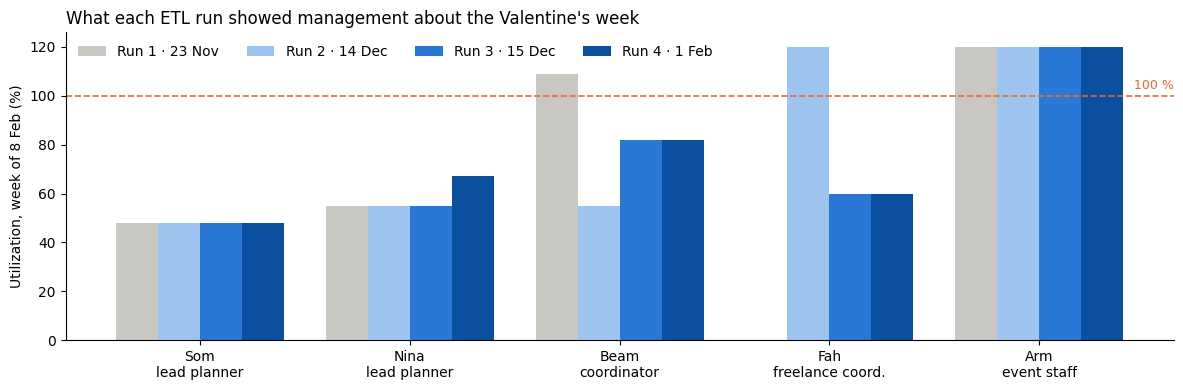

In [14]:
people = ["Som", "Nina", "Beam", "Fah", "Arm"]
fig, ax = plt.subplots(figsize=(12, 4))
colors = ["#c9c7c1", "#9ec5f0", "#2a78d6", "#0b4fa1"]
for i, (label, df) in enumerate(snap.items()):
    vals = df.set_index("employee").reindex(people)["utilization_pct"].astype(float)
    ax.bar([p + (i - 1.5) * 0.2 for p in range(len(people))], vals.fillna(0), width=0.2, color=colors[i], label=label)
ax.axhline(100, color="#eb6834", lw=1.2, ls="--"); ax.text(4.45, 103, "100 %", color="#eb6834", fontsize=9)
ax.set_xticks(range(len(people)), [f"{p}\n" + {"Som": "lead planner", "Nina": "lead planner", "Beam": "coordinator", "Fah": "freelance coord.", "Arm": "event staff"}[p] for p in people])
ax.set_ylabel("Utilization, week of 8 Feb (%)"); ax.legend(frameon=False, ncol=4, loc="upper left")
ax.set_title("What each ETL run showed management about the Valentine's week", loc="left", fontsize=12)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(ROOT / "docs" / "valentines_week_by_run.png", dpi=150); plt.show()

In [15]:
print("Watermarks after run 4 (incremental extraction starts here next time):")
dw('SELECT "SourceTable", "LastUpdatedAt", "LastRunID" FROM etl."Watermark" ORDER BY 1')

Watermarks after run 4 (incremental extraction starts here next time):


,SourceTable,LastUpdatedAt,LastRunID
0,AuspiciousDate,2026-11-07 14:31:43.412774,1
1,ChatMessage,2026-11-07 14:31:43.425185,1
2,Employee,2026-11-07 14:31:43.967761,4
3,EmployeeRole,2026-11-07 14:31:43.412774,1
4,Event,2026-11-07 14:31:43.417224,1
5,EventEmployeeAssignment,2026-11-07 14:31:43.809874,3
6,Inquiry,2026-11-07 14:31:43.425185,1
7,MarketingChannel,2026-11-07 14:31:43.412774,1
8,Package,2026-11-07 14:31:43.412774,1


## 6. Problem 2: following the inquiries run by run

Problem 2 in the report is high inquiry, low conversion: nobody can say where couples drop out, which
channels and packages convert, or whether price, response time, date or scope is the main reason
(Section 2). This section replays the three inquiries of Appendix B.1 to B.3 one business day at a time,
with an incremental run after each day, and shows what the warehouse knows after each run.

It uses separate databases (`aisleco_crm_p2`, `aisleco_dw_p2`) and the same SQL as
`AisleCo_Lean_Walkthrough.sql`, cut at its `-- @step` date markers.

In [16]:
from load_walkthrough import steps
p2 = replace(cfg, crm_dsn="dbname=aisleco_crm_p2", dw_dsn="dbname=aisleco_dw_p2",
             landing_dir=ROOT / "data" / "landing_p2", overlap_seconds=0)
days = steps()
create_crm(p2); init_dw(p2, drop=True)
COUPLE = {1: "Ploy & Ton", 2: "Nok & Bank", 3: "Mint & Jay"}
p2_runs = {}

def p2_day(i):
    d, sql = days[i]
    crm_exec(sql, p2)
    rid = pipeline.run(p2, d)
    ext = staged(rid, p2).query("extracted > 0")["extracted"]
    print(f"run {rid}, as of {d:%d %b %Y}. Rows extracted: " + ", ".join(f"{t} {n}" for t, n in ext.items()))
    inq = dw('''SELECT "InquiryID", "ChannelName" AS channel, "ResponseTimeMinutes" AS response_min,
                       "ResponseTimeBand" AS band, "FurthestStage" AS stage, "Outcome" AS outcome,
                       "LostReason" AS lost_reason, "ClosedBy" AS closed_by, "QuoteShareOfBudget" AS quote_share,
                       "DaysToConvert" AS days_to_convert
                FROM mart.v_inquiry ORDER BY 1''', c=p2)
    inq.insert(0, "couple", inq.pop("InquiryID").map(COUPLE))
    funnel = dw('''SELECT count(*) AS inquiries, sum("IsConsulted") AS consulted, sum("IsQuoted") AS quoted,
                          sum("IsConverted") AS booked, sum("IsOpen") AS still_open, sum("IsLost") AS lost,
                          round(sum("IsConverted")::numeric / nullif(count(*) - sum("IsOpen"), 0), 3) AS conversion_of_decided
                   FROM mart.v_inquiry''', c=p2)
    p2_runs[f"{d:%d %b}"] = inq.outcome.value_counts()
    display(inq.fillna("")); display(funnel)

print("Business days in the script:", ", ".join(f"{d:%d %b %Y}" for d, _ in days))

warehouse aisleco_dw_p2 created (DW v7) with 27 data-quality rules
Business days in the script: 14 Mar 2026, 21 Mar 2026, 24 Mar 2026, 02 Apr 2026, 20 Apr 2026, 21 Nov 2026


14 Mar 2026: Ploy and Ton fill the tablet form at the Wedding Fair booth (budget 500k to 1M, wedding on
16 Jan 2027, Full Planning). Ploy scans the booth QR code and writes on LINE at 14:20, and May replies at
14:31. The CRM's reference data and the four Valentine's weddings already booked are loaded in the same run.

In [17]:
p2_day(0)

run 1, as of 14 Mar 2026. Rows extracted: Event 4, Inquiry 1, Package 3, Employee 5, ChatMessage 2, EmployeeRole 5, AuspiciousDate 4, MarketingChannel 8, EventEmployeeAssignment 12


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Contacted,Open,N/A,N/A,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,1,0,0,0,1,0,None


20 and 21 Mar: Nok asks about Partial Planning on Facebook at 21:40. The bot answers at 21:41 with the
opening hours. May replies at 10:05 the next morning and sends the package sheet; Nok does not write again.
The response time runs from 21:40 to May's reply: the bot greeting does not count.

In [18]:
p2_day(1)

run 2, as of 21 Mar 2026. Rows extracted: Inquiry 1, ChatMessage 5


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Contacted,Open,N/A,N/A,,
1,Nok & Bank,Facebook,745,1-24h,Contacted,Open,N/A,N/A,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,2,0,0,0,2,0,None


24 Mar: Ploy and Ton had their consultation on 21 Mar, and the quote of 95,000 is sent on 24 Mar. One row
changed in the CRM, so one row is extracted.

In [19]:
p2_day(2)

run 3, as of 24 Mar 2026. Rows extracted: Inquiry 1


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Quoted,Open,N/A,N/A,0.1267,
1,Nok & Bank,Facebook,745,1-24h,Contacted,Open,N/A,N/A,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,2,1,1,0,2,0,None


2 Apr: Ploy and Ton sign. The event and two staff assignments are created, and Sales closes the inquiry
as converted.

In [20]:
p2_day(3)

run 4, as of 02 Apr 2026. Rows extracted: Event 1, Inquiry 1, EventEmployeeAssignment 2


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Booked,Booked,N/A,Sales,0.1267,19.0
1,Nok & Bank,Facebook,745,1-24h,Contacted,Open,N/A,N/A,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,2,1,1,1,1,0,1.000


20 Apr: 30 days after Nok's last message, the CRM rule closes the inquiry as lost, reason "No reply",
closed by AutoRule. No reason is invented for her.

In [21]:
p2_day(4)

run 5, as of 20 Apr 2026. Rows extracted: Inquiry 1


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Booked,Booked,N/A,Sales,0.1267,19.0
1,Nok & Bank,Facebook,745,1-24h,Contacted,Lost,No reply,AutoRule,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,2,1,1,1,0,1,0.500


20 and 21 Nov: Mint and Jay come from a TikTok link and ask for Saturday 13 Feb 2027, an auspicious date.
May replies in 7 minutes, checks the weekly workload view (Beam already above 100 % that week, two
weddings on the 13th) and offers 20 Feb instead. They decline, because the 13th is the date their monk
gave them. Sales closes the inquiry as lost, reason "Date unavailable". This is where the two problems
meet: a sale lost to capacity, counted as turned-away peak demand.

In [22]:
p2_day(5)

run 6, as of 21 Nov 2026. Rows extracted: Inquiry 1, ChatMessage 4


,couple,channel,response_min,band,stage,outcome,lost_reason,closed_by,quote_share,days_to_convert
0,Ploy & Ton,Wedding Fair,11,<1h,Booked,Booked,N/A,Sales,0.1267,19.0
1,Nok & Bank,Facebook,745,1-24h,Contacted,Lost,No reply,AutoRule,,
2,Mint & Jay,TikTok,7,<1h,Contacted,Lost,Date unavailable,Sales,,


,inquiries,consulted,quoted,booked,still_open,lost,conversion_of_decided
0,3,1,1,1,0,2,0.333


After the six runs: the outcome of each inquiry run by run, the questions of Appendix B.6 answered from the
warehouse, and a check that loading day by day gives the same inquiry facts as the single load of section 4.

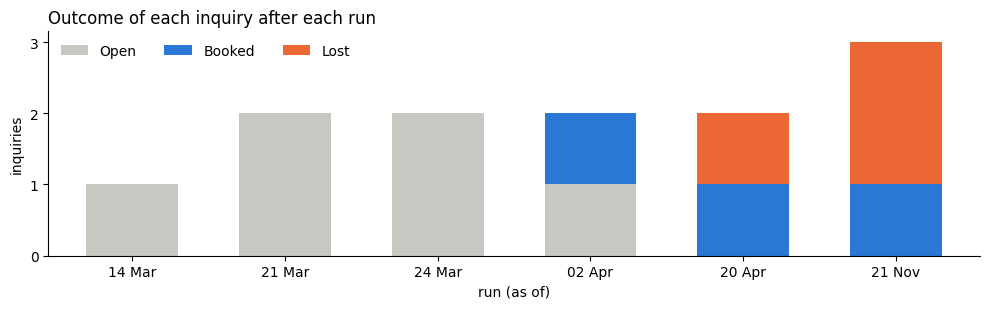

,question (Appendix B.6),answer from the warehouse,decision it supports
0,How fast did we answer?,"Ploy 11 min (<1h), Mint 7 min (<1h), Nok 745 min (1-24h), counted from the couple's first message, not from the bot",Is an evening inbox shift worth it?
1,Why did we lose them?,Nok: No reply (AutoRule). Mint: Date unavailable (Sales). No reason is invented for Nok.,Follow-up before day 30; capacity on peak dates
2,What did Ploy's quote take from her budget?,"95,000 / 750,000 midpoint = 12.7%. Booked 19 days after the fair.",At what fee share do couples walk away on price?
3,How much peak demand did we turn away?,"1 couple, for 13 Feb 2027 (high season: Y, auspicious level: High)",Freelance cover or a peak-date premium


Same inquiry facts as the single load of section 4: True


In [23]:
oc = pd.DataFrame(p2_runs).T.reindex(columns=["Open", "Booked", "Lost"]).fillna(0)
fig, ax = plt.subplots(figsize=(10, 3.2))
oc.plot.bar(stacked=True, ax=ax, color=["#c9c7c1", "#2a78d6", "#eb6834"], width=0.6)
ax.set_ylabel("inquiries"); ax.set_xlabel("run (as of)"); ax.tick_params(axis="x", rotation=0)
ax.set_yticks(range(0, int(oc.sum(axis=1).max()) + 1))
ax.set_title("Outcome of each inquiry after each run", loc="left", fontsize=12)
ax.legend(frameon=False, ncol=3, loc="upper left")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig(ROOT / "docs" / "problem2_by_run.png", dpi=150); plt.show()

v = dw('''SELECT i."InquiryID", i."ResponseTimeMinutes" AS rt, i."ResponseTimeBand" AS band, i."LostReason" AS lr,
                 i."ClosedBy" AS cb, i."QuotedAmount" AS qa, i."BudgetMidpoint" AS bm, i."QuoteShareOfBudget" AS qs,
                 i."DaysToConvert" AS dtc, d."FullDate" AS req, d."IsHighSeason" AS hs, d."AuspiciousLevel" AS al
          FROM mart.v_inquiry i JOIN dim."DimDate" d ON d."DateKey" = i."RequestedEventDateKey"''', c=p2).set_index("InquiryID")
ploy, nok, mint = v.loc[1], v.loc[2], v.loc[3]
turned = int(dw('SELECT sum(inquiries_turned_away) AS n FROM mart.v_turned_away_demand', c=p2).n[0])
b6 = pd.DataFrame([
    ("How fast did we answer?",
     f"Ploy {ploy.rt} min ({ploy.band}), Mint {mint.rt} min ({mint.band}), Nok {nok.rt} min ({nok.band}), "
     "counted from the couple's first message, not from the bot", "Is an evening inbox shift worth it?"),
    ("Why did we lose them?", f"Nok: {nok.lr} ({nok.cb}). Mint: {mint.lr} ({mint.cb}). No reason is invented for Nok.",
     "Follow-up before day 30; capacity on peak dates"),
    ("What did Ploy's quote take from her budget?",
     f"{float(ploy.qa):,.0f} / {float(ploy.bm):,.0f} midpoint = {float(ploy.qs):.1%}. Booked {ploy.dtc:.0f} days after the fair.",
     "At what fee share do couples walk away on price?"),
    ("How much peak demand did we turn away?",
     f"{turned} couple, for {mint.req:%d %b %Y} (high season: {mint.hs}, auspicious level: {mint.al})",
     "Freelance cover or a peak-date premium"),
], columns=["question (Appendix B.6)", "answer from the warehouse", "decision it supports"])
with pd.option_context("display.max_colwidth", 140):
    display(b6)

keys = ["InquiryFactKey", "OutcomeKey", "IndicativePackageKey", "FirstResponderEmployeeKey"]   # surrogate keys differ by load order
a = dw('SELECT * FROM mart.v_inquiry ORDER BY "InquiryID"', c=p2).drop(columns=keys)
b = dw('SELECT * FROM mart.v_inquiry ORDER BY "InquiryID"').drop(columns=keys)
print("Same inquiry facts as the single load of section 4:", a.astype(str).equals(b.astype(str)))

## 7. Data quality: a bad row goes to the dead-letter queue and returns when fixed

A staff reply is logged without the staff member, which the CRM does not enforce. Rule
`chat_staff_without_employee` rejects the row: it is stored with its full content in `etl.RejectedRow`,
the rest of the load continues, and a warning alert is written.

In [24]:
crm_exec('''INSERT INTO transaction."ChatMessage"("ChatMessageID","CustomerAccountID","InquiryID","PlatformMessageID",
            "SentAt","Direction","SenderType","EmployeeID") VALUES (900,3,3,'L-0900','2026-11-22 10:00','Out','Staff',NULL)''', cfg)
run5 = pipeline.run(demo, date(2027, 2, 1))
display(staged(run5).query("extracted > 0"))
dw('''SELECT d."RunID", r."RuleName", d."SourceTable", d."SourceKey", d."Payload", d."ResolvedRunID"
      FROM etl."RejectedRow" d JOIN etl."DqRule" r USING ("RuleID")''')

WARNING ALERT [warning] run 5: ChatMessage: 1 row(s) rejected by chat_staff_without_employee


,extracted,rejected,inserted,updated,unchanged,deleted
ChatMessage,1,1,0,0,0,0


,RunID,RuleName,SourceTable,SourceKey,Payload,ResolvedRunID
0,5,chat_staff_without_employee,ChatMessage,900,"{'SentAt': '2026-11-22T10:00:00', 'Direction': 'Out', 'InquiryID':...",None


The record is corrected in the CRM. Its `UpdatedAt` changes, so the next run extracts it, loads it and marks the dead-letter row as resolved.

In [25]:
crm_exec('UPDATE transaction."ChatMessage" SET "EmployeeID"=5 WHERE "ChatMessageID"=900', cfg)
run6 = pipeline.run(demo, date(2027, 2, 1))
dw('''SELECT d."RunID" AS rejected_in_run, d."SourceKey", d."ResolvedRunID" AS loaded_in_run FROM etl."RejectedRow" d''')

,rejected_in_run,SourceKey,loaded_in_run
0,5,900,6


## 8. The quality gate stops a systematic problem

An upstream change starts sending a new sender type (`AutoReply`) on every message. 30 of 30 new rows are
rejected, above the 5 % limit, so the `dq_gate` step stops the run. No dimension or fact is changed and
the watermark does not move, so these rows are read again once the cause is fixed.

In [26]:
before = dw('SELECT count(*) AS n, sum("ResponseTimeMinutes") AS s FROM fact."FactInquiry"')
crm_exec('''INSERT INTO transaction."ChatMessage"("CustomerAccountID","InquiryID","PlatformMessageID","SentAt","Direction","SenderType")
            SELECT 3, 3, 'X-'||k, '2026-11-22 10:00'::timestamp + k * interval '1 minute', 'Out', 'AutoReply' FROM generate_series(1,30) k''', cfg)
try:
    pipeline.run(demo, date(2027, 2, 1))
except Exception as e:
    print(type(e).__name__, "->", e)
run7 = int(dw('SELECT max("RunID") FROM etl."Run"').iloc[0, 0])
display(run_log(run7)[["Step", "Status", "error"]])
print("FactInquiry before / after:", before.values.tolist(), dw('SELECT count(*) AS n, sum("ResponseTimeMinutes") AS s FROM fact."FactInquiry"').values.tolist())

WARNING ALERT [warning] run 7: ChatMessage: 30 row(s) rejected by chat_invalid_values


ERROR ALERT [error] run 7: step dq_gate failed: data-quality gate failed: reject_rate: ChatMessage 30/30 rejected (limit 5%)


DataQualityError -> data-quality gate failed: reject_rate: ChatMessage 30/30 rejected (limit 5%)


,Step,Status,error
0,extract,success,None
1,stage,success,None
2,dq_gate,failed,DataQualityError: data-quality gate failed: reject_rate: ChatMessa...


FactInquiry before / after: [[3, 763]] [[3, 763]]


The cause is fixed upstream and the bad rows are removed from the CRM. The next run removes them from staging, closes their dead-letter rows because the keys no longer exist, and succeeds.

In [27]:
crm_exec('''DELETE FROM transaction."ChatMessage" WHERE "SenderType"='AutoReply' ''', cfg)
run8 = pipeline.run(demo, date(2027, 2, 1))
dw('SELECT "RunID", "Status", "Message" FROM etl."Run" WHERE "RunID" >= %s ORDER BY 1', (run7,))

,RunID,Status,Message
0,7,failed,step dq_gate: data-quality gate failed: reject_rate: ChatMessage 3...
1,8,success,None


## 9. A crash during the load, then resume from the checkpoint

Fah's assignment grows from 16 h to 20 h. The `ETL_FAIL_AT` test hook makes `fact_weekly_workload` fail
just before it commits. The step's transaction is rolled back, so nothing is half-written. `resume` skips
the steps that already succeeded and finishes the run.

The extra planning hours also fall in four January weeks that have already ended. Those rows stay frozen
and the run reports them as a late change. The warning appears twice in the log below because the failed
attempt raised it too; that attempt was rolled back, so `etl.Alert` holds it once. Later runs record the
same count in `etl.DqResult` without alerting again.

In [28]:
crm_exec('UPDATE transaction."EventEmployeeAssignment" SET "WorkloadHours"=20 WHERE "EventID"=104 AND "EmployeeID"=6', cfg)
try:
    pipeline.run(replace(demo, fail_at="fact_weekly_workload"), date(2027, 2, 1))
except RuntimeError as e:
    print("crashed:", e)
run9 = int(dw('SELECT max("RunID") FROM etl."Run"').iloc[0, 0])
pipeline.resume(demo, run9)
display(run_log(run9)[["Step", "Attempt", "Status", "sec", "changes", "error"]])
with pd.option_context("display.max_colwidth", 130):     # full text, so "late change" is visible
    display(dw('''SELECT "RunID", "Severity", split_part("Message", ';', 1) AS "Message" FROM etl."Alert" ORDER BY "AlertID"'''))

WARNING ALERT [warning] run 9: FactEmployeeWeeklyWorkload: 4 row(s) of weeks that have ended no longer match the CRM (late change); kept frozen. Run a full rebuild on purpose if they must be corrected


ERROR ALERT [error] run 9: step fact_weekly_workload failed: injected failure in step fact_weekly_workload (ETL_FAIL_AT)


WARNING ALERT [warning] run 9: FactEmployeeWeeklyWorkload: 4 row(s) of weeks that have ended no longer match the CRM (late change); kept frozen. Run a full rebuild on purpose if they must be corrected


crashed: injected failure in step fact_weekly_workload (ETL_FAIL_AT)


,Step,Attempt,Status,sec,changes,error
0,extract,1,success,0.014,,None
1,stage,1,success,0.022,,None
2,dq_gate,1,success,0.004,,None
3,dim_date,1,success,0.012,,None
4,dim_package,1,success,0.002,,None
5,dim_employee,1,success,0.002,,None
6,fact_inquiry,1,success,0.010,{'unchanged': 3},None
7,fact_event_booking,1,success,0.007,"{'updated': 1, 'unchanged': 4}",None
8,fact_weekly_workload,1,failed,0.010,,RuntimeError: injected failure in step fact_weekly_workload (ETL_F...
9,fact_weekly_workload,2,success,0.011,"{'updated': 1, 'unchanged': 187, 'frozen_changed': 4}",None


,RunID,Severity,Message
0,5,warning,ChatMessage: 1 row(s) rejected by chat_staff_without_employee
1,7,warning,ChatMessage: 30 row(s) rejected by chat_invalid_values
2,7,error,step dq_gate failed: data-quality gate failed: reject_rate: ChatMessage 30/30 rejected (limit 5%)
3,9,error,step fact_weekly_workload failed: injected failure in step fact_weekly_workload (ETL_FAIL_AT)
4,9,warning,FactEmployeeWeeklyWorkload: 4 row(s) of weeks that have ended no longer match the CRM (late change)


## 10. Extract fails: the CRM cannot be reached

The connection is retried with exponential backoff, which covers short outages. After the last attempt the
run fails in the extract step, before anything is written. Staging and the warehouse are unchanged, an
error alert is stored, and the watermarks do not move, so the next run reads the same rows. The WARNING
and ERROR lines are the pipeline's log messages.

In [29]:
wm_before = dw('SELECT "SourceTable", "LastUpdatedAt" FROM etl."Watermark" ORDER BY 1')
down = replace(demo, crm_dsn="host=127.0.0.1 port=1 dbname=aisleco_crm", connect_retries=3, retry_base_seconds=1)
try:
    pipeline.run(down, date(2027, 2, 1))
except ConnectionError as e:
    print("run failed:", e)
failed = int(dw('SELECT max("RunID") FROM etl."Run"').iloc[0, 0])
display(dw('SELECT "RunID", "Status", "Message" FROM etl."Run" WHERE "RunID"=%s', (failed,)))
display(run_log(failed)[["Step", "Attempt", "Status", "error"]])
display(dw('SELECT "Severity", "Message" FROM etl."Alert" WHERE "RunID"=%s', (failed,)))
print("watermarks unchanged:", wm_before.equals(dw('SELECT "SourceTable", "LastUpdatedAt" FROM etl."Watermark" ORDER BY 1')))

WARNING connect CRM failed (attempt 1/3), retrying in 1s: connection failed: connection to server at "127.0.0.1", port 1 failed: could not receive data from server: Connection refused


WARNING connect CRM failed (attempt 2/3), retrying in 2s: connection failed: connection to server at "127.0.0.1", port 1 failed: could not receive data from server: Connection refused


ERROR ALERT [error] run 10: step extract failed: could not connect to CRM after 3 attempts: connection failed: connection to server at "127.0.0.1", port 1 failed: Connection refused
	Is the server running on that host and accepting TCP/IP connections?


run failed: could not connect to CRM after 3 attempts: connection failed: connection to server at "127.0.0.1", port 1 failed: Connection refused
	Is the server running on that host and accepting TCP/IP connections?


,RunID,Status,Message
0,10,failed,step extract: could not connect to CRM after 3 attempts: connectio...


,Step,Attempt,Status,error
0,extract,1,failed,ConnectionError: could not connect to CRM after 3 attempts: connec...


,Severity,Message
0,error,step extract failed: could not connect to CRM after 3 attempts: co...


watermarks unchanged: True


### Where each stage can fail, and what the pipeline does

| Stage | Failure | What happens | Where it is logged | How to recover |
|---|---|---|---|---|
| E: extract | CRM down or network outage | Retry with backoff, then the run fails before anything is written (section 10) | `etl.StepRun`, `etl.Run`, `etl.Alert` | Restore the connection and run again; the watermark has not moved |
| E to L: landing | File damaged or changed after extract | Checked against the manifest checksum; the stage step refuses it (test `damaged_landing_file`) | `etl.StepRun.Error`, `etl.Alert` | Run again; the files are extracted again |
| T: row rules | One bad row (missing date, unknown status, orphan) | The row goes to the dead-letter queue `etl.RejectedRow`; the rest loads (section 7) | `etl.RejectedRow`, `etl.DqResult`, warning alert | Correct it in the CRM; the next run loads it and marks it resolved |
| T: quality gate | Systematic problem (reject rate above 5 %, orphans in staging) | The run stops before any dimension or fact changes (section 8) | `etl.DqResult`, error alert | Fix the cause upstream and run again |
| L: load | Crash inside a step | The step's transaction is rolled back; `resume` skips the finished steps (section 9) | `etl.StepRun` (attempt 1 failed, attempt 2 succeeded) | `python -m etl resume RUN_ID` |
| L: reconcile | Target does not match source | The run is marked failed and the watermarks do not move | `etl.DqResult`, error alert | Investigate; the next run reads the same rows again |
| Volume | More changes than one run may take | Batch cap; the rest waits in the backlog queue (section 13) | Warning alert, `backlog` in `etl.StepRun.Metrics` | None; the following runs drain it |

## 11. Idempotency: running again changes nothing

Same CRM, same as-of date. Every row is compared and none is written, so surrogate keys stay the same and a
retry cannot duplicate data. This run uses the production 5-minute overlap, so recent rows are read again;
all of them come out `unchanged`. `frozen_changed` is the late change from section 9, still frozen.

In [30]:
run10 = pipeline.run(cfg, date(2027, 2, 1))      # production overlap (5 min) -> rows are re-read, none rewritten
log = run_log(run10); display(log[["Step", "RowsIn", "RowsOut", "changes"]])
print("Staging:"); staged(run10)[["extracted", "inserted", "updated", "unchanged", "deleted"]]

,Step,RowsIn,RowsOut,changes
0,extract,60.0,60.0,
1,stage,60.0,0.0,
2,dq_gate,NaN,NaN,
3,dim_date,NaN,0.0,
4,dim_package,NaN,0.0,
5,dim_employee,NaN,0.0,
6,fact_inquiry,3.0,0.0,{'unchanged': 3}
7,fact_event_booking,5.0,0.0,{'unchanged': 5}
8,fact_weekly_workload,236.0,0.0,"{'unchanged': 188, 'frozen_changed': 4}"
9,reconcile,NaN,NaN,


Staging:


,extracted,inserted,updated,unchanged,deleted
Event,5,0,0,5,0
Inquiry,3,0,0,3,0
Package,3,0,0,3,0
Employee,6,0,0,6,0
ChatMessage,12,0,0,12,0
EmployeeRole,5,0,0,5,0
AuspiciousDate,4,0,0,4,0
MarketingChannel,8,0,0,8,0
EventEmployeeAssignment,14,0,0,14,0


## 12. Source-to-target check, and the KPIs of both problems on a business year

The v3 notebook simulates a business year (619 inquiries, 2,652 chat messages, 345 staff assignments) and
computes its own Gold zone in pandas. The pipeline loads the same simulated CRM into separate databases
(`aisleco_crm_sim`, `aisleco_dw_sim`), and every value of the three facts is compared.

In [31]:
from load_snapshot import load
from crosscheck import compare_with_gold
ZONES = ROOT / "data" / "sim" / "zones_v3"
sim = replace(cfg, crm_dsn="dbname=aisleco_crm_sim", dw_dsn="dbname=aisleco_dw_sim", landing_dir=ROOT / "data" / "landing_sim")
print("CRM rows loaded:", load(ZONES, 1, sim))
init_dw(sim, drop=True)
sim_run = pipeline.run(sim, date(2027, 1, 15), "full")
checks, fails = compare_with_gold(ZONES, sim)
print(f"\nvalues compared: {checks:,}   differences: {len(fails)}")
run_log(sim_run, sim)[["Step", "sec", "RowsIn", "RowsOut"]]

CRM rows loaded: {'MarketingChannel': 8, 'Package': 6, 'EmployeeRole': 7, 'AuspiciousDate': 181, 'Employee': 10, 'CustomerChannelAccount': 524, 'Inquiry': 619, 'ChatMessage': 2652, 'Event': 99, 'EventEmployeeAssignment': 345}
warehouse aisleco_dw_sim created (DW v7) with 27 data-quality rules



values compared: 28,638   differences: 0


,Step,sec,RowsIn,RowsOut
0,extract,0.019,3927.0,3927.0
1,stage,0.043,3927.0,3927.0
2,dq_gate,0.006,NaN,NaN
3,dim_date,0.013,NaN,1461.0
4,dim_package,0.002,NaN,6.0
5,dim_employee,0.004,NaN,10.0
6,fact_inquiry,0.034,619.0,619.0
7,fact_event_booking,0.016,99.0,99.0
8,fact_weekly_workload,0.028,1160.0,1160.0
9,reconcile,0.019,NaN,NaN


### The KPIs of both problems on the simulated year

Every KPI of Section 2.1, read from the `mart` views of the simulated year. The sentence under each table is
computed from the same numbers. The data is simulated: it shows that the warehouse computes what Section 2.1
specifies, not what Aisle & Co.'s real figures are (Section 5.6).

#### Problem 2: high inquiry, low conversion

In [32]:
ch = dw('SELECT * FROM mart.v_funnel_by_channel ORDER BY inquiries DESC', c=sim); display(ch)
big = ch[ch.inquiries >= 30].sort_values("conversion_rate_decided")
print(f"Conversion of decided inquiries runs from {float(big.conversion_rate_decided.iloc[0]):.1%} ({big.ChannelName.iloc[0]}) "
      f"to {float(big.conversion_rate_decided.iloc[-1]):.1%} ({big.ChannelName.iloc[-1]}) among channels with 30 or more inquiries.")
mo = dw('''SELECT d."YearMonth" AS inquiry_month, count(*) AS inquiries, sum(i."IsConverted") AS booked,
                  sum(i."IsOpen") AS still_open,
                  round(sum(i."IsConverted")::numeric / nullif(count(*) - sum(i."IsOpen"), 0), 3) AS conversion_of_decided
           FROM mart.v_inquiry i JOIN dim."DimDate" d ON d."DateKey" = i."InquiryDateKey" GROUP BY 1 ORDER BY 1''', c=sim)
display(mo)
print(f"{int(mo.still_open.sum())} inquiries are still open, {int(mo.still_open.tail(2).sum())} of them from the last two months. "
      "They are kept apart because they have not had time to convert.")

,ChannelName,inquiries,consulted,quoted,booked,still_open,conversion_rate_decided
0,Wedding Fair,183,96,71,22,0,0.120
1,LINE OA,129,76,63,24,3,0.190
2,Facebook,107,61,47,17,1,0.160
3,Referral,62,30,25,12,2,0.200
4,Instagram,61,31,28,10,1,0.167
5,TikTok,35,12,5,0,3,0.000
6,Walk-in,24,12,9,1,1,0.043
7,Website,18,3,2,1,2,0.063


Conversion of decided inquiries runs from 0.0% (TikTok) to 20.0% (Referral) among channels with 30 or more inquiries.


,inquiry_month,inquiries,booked,still_open,conversion_of_decided
0,2026-01,72,11,0,0.153
1,2026-02,30,2,0,0.067
2,2026-03,83,15,0,0.181
3,2026-04,30,5,0,0.167
4,2026-05,23,3,0,0.130
5,2026-06,66,8,0,0.121
6,2026-07,49,10,0,0.204
7,2026-08,75,6,0,0.080
8,2026-09,38,5,0,0.132
9,2026-10,75,10,0,0.133


13 inquiries are still open, 13 of them from the last two months. They are kept apart because they have not had time to convert.


In [33]:
pk = dw('SELECT * FROM mart.v_conversion_by_package ORDER BY inquiries DESC', c=sim); display(pk)
print("Conversion by the package the couple asked about: " +
      ", ".join(f"{r.PackageFamily} {float(r.conversion_rate):.1%}" for r in pk.itertuples()) + ".")
rt = dw('''SELECT * FROM mart.v_response_vs_conversion
           ORDER BY array_position(array['<1h','1-24h','>24h','Not logged','In person'], "ResponseTimeBand"::text)''', c=sim)
display(rt)
r = rt.set_index("ResponseTimeBand")
print(f"Answered within 1 hour: {float(r.conversion_rate['<1h']):.1%} converted (median reply {r.median_minutes['<1h']:.0f} min). "
      f"Answered in 1 to 24 hours: {float(r.conversion_rate['1-24h']):.1%} (median {r.median_minutes['1-24h']:.0f} min).")

,PackageFamily,inquiries,booked,conversion_rate
0,Full Planning,232,35,0.151
1,Unknown,127,13,0.102
2,Day-of Coordination,112,15,0.134
3,Partial Planning,110,19,0.173
4,Custom,38,5,0.132


Conversion by the package the couple asked about: Full Planning 15.1%, Unknown 10.2%, Day-of Coordination 13.4%, Partial Planning 17.3%, Custom 13.2%.


,ResponseTimeBand,inquiries,median_minutes,consult_rate,conversion_rate
0,<1h,214,17.0,0.556,0.182
1,1-24h,285,373.0,0.488,0.123
2,>24h,18,2600.0,0.667,0.167
3,Not logged,7,NaN,0.571,0.286
4,In person,95,NaN,0.495,0.084


Answered within 1 hour: 18.2% converted (median reply 17 min). Answered in 1 to 24 hours: 12.3% (median 373 min).


In [34]:
sd = dw('SELECT * FROM mart.v_stage_dropoff', c=sim); display(sd)
s = sd.iloc[0]
print(f"Of {s.inquiries} inquiries, {s.consulted / s.inquiries:.0%} reached a consultation, {s.quoted / s.inquiries:.0%} a quote "
      f"and {s.booked / s.inquiries:.0%} a booking. A booking took {s.avg_days_to_convert} days from the first contact on average.")
lr = dw('SELECT * FROM mart.v_lost_reasons ORDER BY lost DESC', c=sim); display(lr)
print(f"{float(lr[lr.ClosedBy == 'AutoRule'].share_of_all_lost.sum()):.0%} of lost inquiries were closed by the 30-day rule "
      "(the couple went silent); the rest carry a reason given by Sales.")
qs = dw('SELECT * FROM mart.v_quote_share ORDER BY outcome', c=sim); display(qs)
q = qs.set_index("outcome")
print(f"Median quote share of budget: {float(q.median_quote_share['Booked']):.1%} for booked couples, "
      f"{float(q.median_quote_share['Lost on price']):.1%} for couples lost on price.")

,inquiries,consulted,quoted,booked,avg_days_to_consultation,avg_days_consultation_to_quote,avg_days_quote_to_booking,avg_days_to_convert
0,619,321,250,87,8.7,4.1,12.5,25.7


Of 619 inquiries, 52% reached a consultation, 40% a quote and 14% a booking. A booking took 25.7 days from the first contact on average.


,ClosedBy,LostReason,lost,share_of_all_lost
0,AutoRule,No reply,396,0.769
1,Sales,Price,49,0.095
2,Sales,Date unavailable,35,0.068
3,Sales,Chose competitor,19,0.037
4,Sales,Budget changed,8,0.016
5,Sales,Scope mismatch,8,0.016


77% of lost inquiries were closed by the 30-day rule (the couple went silent); the rest carry a reason given by Sales.


,outcome,quoted_inquiries,median_quote_share,mean_quote_share
0,Booked,87,0.13250,0.133
1,Lost on price,38,0.16705,0.160
2,Other,125,0.13070,0.142


Median quote share of budget: 13.2% for booked couples, 16.7% for couples lost on price.


#### Problem 1: seasonal demand and capacity

In [35]:
pa = dw('SELECT * FROM mart.v_peak_acceptance', c=sim); display(pa)
p = pa.iloc[0]
print(f"Of {p.peak_inquiries} inquiries for a high-season or auspicious date, {float(p.acceptance_rate):.1%} became a booking; "
      f"{p.lost_date_unavailable} were lost because the date was unavailable.")
ta = dw('SELECT * FROM mart.v_turned_away_demand ORDER BY inquiries_turned_away DESC, requested_month LIMIT 6', c=sim); display(ta)
sh = dw('SELECT * FROM mart.v_staff_hours_per_wedding ORDER BY avg_total_hours DESC', c=sim); display(sh)
print(f"Staff hours per wedding run from {sh.avg_total_hours.min()} to {sh.avg_total_hours.max()} hours on average, "
      "by package, complexity and guest count.")
wk = dw('''SELECT week_start, count(*) FILTER (WHERE "TotalAssignedHours" > "StandardWeeklyHours") AS people_over_100pct,
                  round(max("UtilizationRate") * 100) AS highest_utilization_pct, sum("OvertimeHours") AS overtime_hours
           FROM mart.v_weekly_workload GROUP BY 1
           ORDER BY people_over_100pct DESC, highest_utilization_pct DESC LIMIT 6''', c=sim); display(wk)
print(f"The busiest week starts {wk.week_start[0]:%d %b %Y}: {wk.people_over_100pct[0]} people above 100 %, "
      f"{float(wk.overtime_hours[0]):.0f} overtime hours.")

,peak_inquiries,booked_not_cancelled,acceptance_rate,lost_date_unavailable
0,209,22,0.105,22


Of 209 inquiries for a high-season or auspicious date, 10.5% became a booking; 22 were lost because the date was unavailable.


,requested_month,auspicious_level,inquiries_turned_away
0,2026-12,Not auspicious,9
1,2027-06,Not auspicious,4
2,2026-11,Not auspicious,3
3,2027-01,Not auspicious,3
4,None,Not auspicious,2
5,2026-07,Not auspicious,1


,PackageFamily,ComplexityLevel,guest_band,weddings,avg_total_hours,avg_planning_hours,avg_event_day_hours
0,Custom,High,450+,1,198.5,150.5,48.0
1,Custom,High,250-449,2,164.1,116.1,48.0
2,Full Planning,High,450+,10,162.6,114.6,48.0
3,Custom,High,<250,2,160.7,112.7,48.0
4,Full Planning,Medium,250-449,24,133.0,85.8,47.2
5,Full Planning,Low,<250,7,132.6,85.3,47.3
6,Partial Planning,High,450+,4,72.9,36.9,36.0
7,Day-of Coordination,High,450+,6,72.8,36.8,36.0
8,Partial Planning,Low,250-449,1,58.3,22.5,35.8
9,Partial Planning,Low,<250,4,57.3,22.3,35.0


Staff hours per wedding run from 56.1 to 198.5 hours on average, by package, complexity and guest count.


,week_start,people_over_100pct,highest_utilization_pct,overtime_hours
0,2027-01-04,4,125,23.81
1,2026-12-21,3,143,45.04
2,2026-12-28,2,116,8.21
3,2027-05-24,2,116,7.71
4,2027-01-11,1,131,13.83
5,2027-02-15,1,118,7.38


The busiest week starts 04 Jan 2027: 4 people above 100 %, 24 overtime hours.


## 13. Performance: capacity, latency and the backlog queue

The design target is that one run finishes within 2 minutes, from a CRM commit to the change being visible
in the warehouse. The stress test (`scripts/benchmark.py --stress`) loads millions of rows and takes about
25 minutes, so it is run beforehand and its saved results are shown here. It measures two things, because a
run spends time in two ways:

* History size: Transform rebuilds each fact from staging and the merge then writes only the changed rows,
  so even a small incremental run grows with the history.
* Burst size: Extract and stage handle only the changed rows, so their cost grows with the number of changes.

Stress test: latency target 120 s per run. Machine: this laptop, local PostgreSQL 16.

A. History size (simulated CRM copied N times)
 copies    CRM rows  full run s  incremental s
     10      42,692         0.9            0.5
    100     425,102        11.4            9.3
    250   1,062,452        44.2           29.0
    500   2,124,702       105.1           33.8
   1000   4,249,202       218.9           50.6

B. Burst size (history x100; changes committed as 1,000-row CRM transactions; no cap)
 changed rows  incremental s    rows/s
       10,000            5.7     1,765
       50,000            6.1     8,204
      100,000            6.8    14,730
      200,000            8.8    22,623
      326,000           10.1    32,273

C. The largest burst (326,000 changes) again, drained with the batch cap of 100,000 rows per run (5-minute overlap, runs spaced as scheduled)
 run  rows read*  queued after  seconds
   1     119,763       206,237      5.9
   2     119,767       106,233      7.6


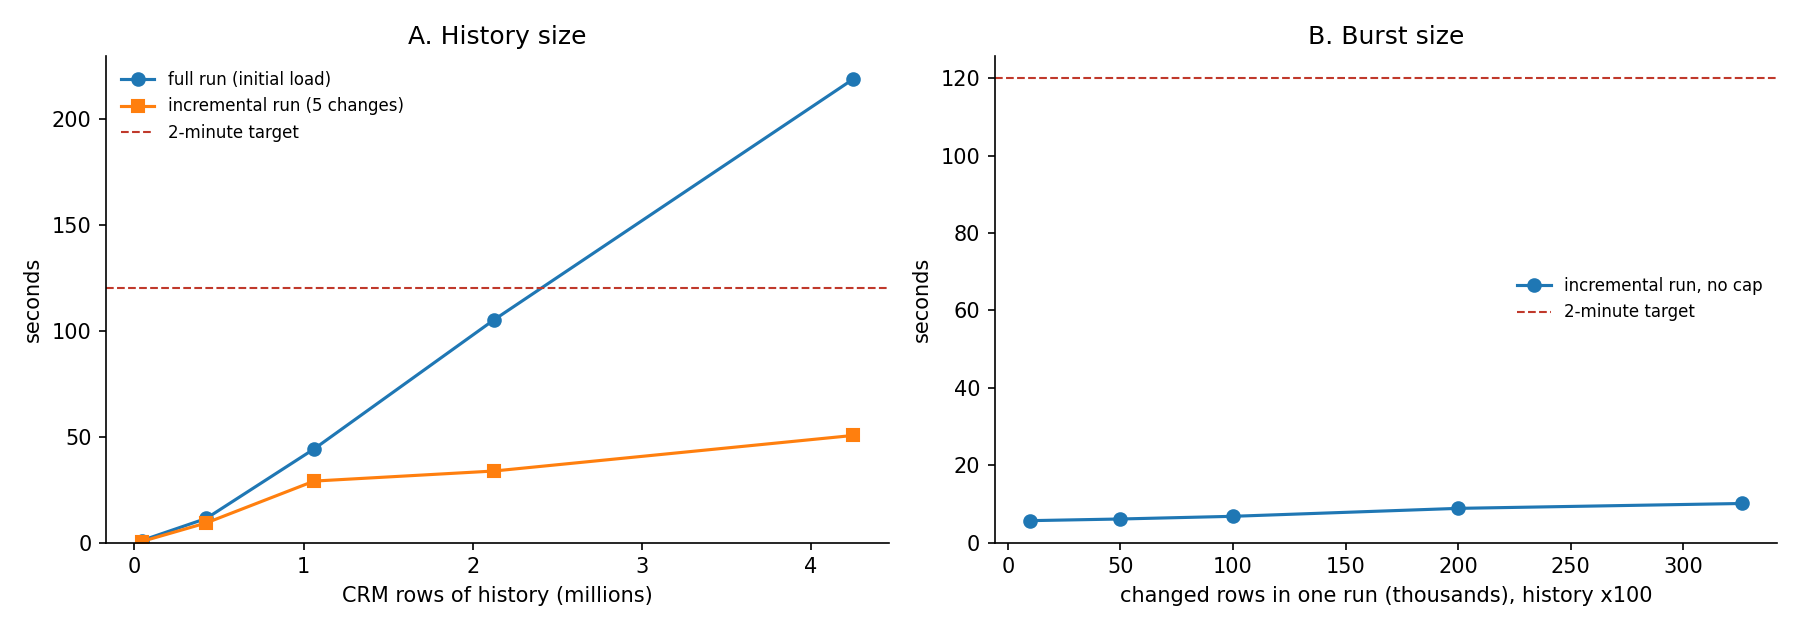

Result: an incremental run took 50.6 s at 4,249,202 CRM rows of history (1000 copies of the simulated year), and one run absorbed 326,000 changes in 10.1 s. The full load stayed within 2 minutes up to 2,124,702 rows (105.1 s) and took 218.9 s at 4,249,202 rows; it runs once, outside the target. The limits printed under 'Limits' go beyond the measured points and are a linear extrapolation.


In [36]:
import re
from IPython.display import Image
st = (ROOT / "docs" / "stress_test.txt").read_text()
print(st); display(Image(filename=str(ROOT / "docs" / "stress_test.png")))
hist = re.findall(r"^\s*(\d+)\s+([\d,]+)\s+([\d.]+)\s+([\d.]+)\s*$", st.split("\nA. ")[1].split("\nB. ")[0], re.M)
bursts = re.findall(r"^\s*([\d,]+)\s+([\d.]+)\s+([\d,]+)\s*$", st.split("\nB. ")[1].split("\nC. ")[0], re.M)
top, ok, big = hist[-1], [h for h in hist if float(h[2]) <= 120][-1], bursts[-1]
print(f"Result: an incremental run took {top[3]} s at {top[1]} CRM rows of history ({top[0]} copies of the simulated year), "
      f"and one run absorbed {big[0]} changes in {big[1]} s. The full load stayed within 2 minutes up to {ok[1]} rows "
      f"({ok[2]} s) and took {top[2]} s at {top[1]} rows; it runs once, outside the target. The limits printed under "
      "'Limits' go beyond the measured points and are a linear extrapolation.")

### Above the limit: the backlog queue

`ETL_MAX_ROWS_PER_RUN` (100,000 by default) limits the changed transaction rows one incremental run takes,
oldest first. Later changes stay in the CRM behind the watermark, and the next run continues from the
cutoff. Four rules keep this correct:

* a CRM transaction is never split: rows with the same `UpdatedAt` go together;
* a taken row brings its parent rows into the same batch, so no child is rejected as an orphan;
* queued keys are marked `Pending`, so reconciliation does not count them as missing;
* the watermark moves to the cutoff, and the overlap is measured from the previous snapshot, so every run
  moves forward without reading earlier batches again.

On the simulated year from section 12: 1,500 changes committed as 15 CRM transactions, with a cap of 500.

In [37]:
from benchmark import burst
sim0 = replace(sim, overlap_seconds=0)
burst(sim0, 1500, chunk=100)
capped = replace(sim0, max_rows_per_run=500)
rows, backlog = [], None
while backlog != 0:
    t = time.perf_counter(); rid = pipeline.run(capped, date(2027, 1, 15)); t = time.perf_counter() - t
    m = dw('''SELECT "Metrics" FROM etl."StepRun" WHERE "RunID"=%s AND "Step"='extract' AND "Status"='success' ''', (rid,), sim).iloc[0, 0]
    backlog = m["backlog"]
    rows.append({"run": rid, "chat messages taken": m["per_table"]["ChatMessage"], "inquiries (parents pulled)": m["per_table"]["Inquiry"],
                 "queued after the run": backlog, "seconds": round(t, 2)})
display(pd.DataFrame(rows))
dw('SELECT "RunID", "Message" FROM etl."Alert" WHERE "Message" LIKE %s ORDER BY 1', ("%backlog%",), sim)

WARNING ALERT [warning] run 2: batch cap 500: 1,000 changed row(s) after 2026-11-07 14:31:50.301566 are queued in the CRM backlog; the next run continues from there


WARNING ALERT [warning] run 3: batch cap 500: 500 changed row(s) after 2026-11-07 14:31:50.307109 are queued in the CRM backlog; the next run continues from there


,run,chat messages taken,inquiries (parents pulled),queued after the run,seconds
0,2,500,0,1000,0.18
1,3,500,0,500,0.17
2,4,500,0,0,0.17


,RunID,Message
0,2,"batch cap 500: 1,000 changed row(s) after 2026-11-07 14:31:50.3015..."
1,3,batch cap 500: 500 changed row(s) after 2026-11-07 14:31:50.307109...


Run times in this notebook, against the 2-minute target:

In [38]:
slowest = lambda c: float(dw('''SELECT max(extract(epoch FROM "FinishedAt" - "StartedAt")) AS s FROM etl."Run"
                                WHERE "Status"='success' ''', c=c).s[0])
pd.DataFrame([
    {"measure": "slowest run, Appendix B (incremental)", "seconds": round(slowest(cfg), 2)},
    {"measure": "slowest run, simulated year (full + capped runs)", "seconds": round(slowest(sim), 2)},
    {"measure": "whole notebook so far (sections 3 to 13)", "seconds": round(time.perf_counter() - T0, 1)},
]).assign(target_s=120, within_target=lambda d: d.seconds <= 120)

,measure,seconds,target_s,within_target
0,"slowest run, Appendix B (incremental)",0.16,120,True
1,"slowest run, simulated year (full + capped runs)",0.21,120,True
2,whole notebook so far (sections 3 to 13),9.00,120,True


## 14. How we test

The tests are in `tests/` (pytest) and use their own databases (`aisleco_*_test`), so the demo databases
are not touched. Each test builds its own CRM, runs the pipeline, and compares the warehouse with an answer
worked out in advance.

| Test type (brief) | How | Data | Pass means |
|---|---|---|---|
| Functional: transformation rules | One small case per rule with a known answer, e.g. a bot greeting is not a reply (`test_transform_rules.py`) | 14 hand-made CRM cases | The warehouse value equals the expected value |
| Functional: end to end | Appendix B replayed through four incremental runs (`test_walkthrough.py`) | The Appendix B story | Every Appendix B figure reproduced (Beam 109 %, Arm 120 %, Nina 67 % on 36 h and others); incremental equals full refresh; a second run changes nothing |
| Functional: source to target | The same CRM computed twice, independently: in pandas (v3 notebook) and by the pipeline (`test_source_to_target.py`, section 12) | Simulated business year | 28,638 values, 0 differences |
| Performance | History and burst grown until a run passes 2 minutes (`scripts/benchmark.py --stress`, section 13); a burst drained through the batch cap (`test_backlog.py`) | Up to 1,000 copies of the simulated year | Measured limits; no capped run takes more than the cap; the drained warehouse equals a full refresh |
| Error handling and recovery | The failure is injected: closed port, bad row, crash hook (`ETL_FAIL_AT`), damaged file; then the outcome is checked (`test_error_handling.py`) | Appendix B data | Warehouse unchanged or correctly resumed, alert written, watermark not moved, dead-letter row resolved after the fix |

Three tests in full, one per test type. Every test is listed and shown further down. The code is read
from the test files.

In [39]:
import ast
def show_test(file, name):
    src = (ROOT / "tests" / file).read_text()
    fn = next(n for n in ast.walk(ast.parse(src)) if isinstance(n, ast.FunctionDef) and n.name == name)
    print(f"# tests/{file}\n" + ast.get_source_segment(src, fn) + "\n")

print("=== FUNCTIONAL: a bot greeting is not a response ===")
print("# the CRM rows this test is given (inquiry 1, from FIXTURE in the same file):")
fixture = (ROOT / "tests" / "test_transform_rules.py").read_text()
print("\n".join(l for l in fixture.splitlines() if "(1,1,'m" in l))
print("#  -> couple 21:40, bot 21:41 (ignored), first staff reply 10:05 next day = 745 min, band 1-24h\n")
show_test("test_transform_rules.py", "test_bot_greeting_is_not_a_response")

print("=== ERROR HANDLING: crash during the load, then resume from the checkpoint ===")
show_test("test_error_handling.py", "test_crash_during_load_then_resume_from_checkpoint")

print("=== CAPACITY: a burst larger than the cap is queued, then drained ===")
show_test("test_backlog.py", "test_burst_is_queued_then_drained")

=== FUNCTIONAL: a bot greeting is not a response ===
# the CRM rows this test is given (inquiry 1, from FIXTURE in the same file):
 (1,1,'m1','2026-03-20 21:40','In','Customer',NULL),(1,1,'m2','2026-03-20 21:41','Out','Bot',NULL),
 (1,1,'m3','2026-03-21 10:05','Out','Staff',5),
#  -> couple 21:40, bot 21:41 (ignored), first staff reply 10:05 next day = 745 min, band 1-24h

# tests/test_transform_rules.py
def test_bot_greeting_is_not_a_response(dw):
    """Scenario: Inquiry 1: the couple writes at 21:40, the bot answers at 21:41, a staff member replies at 10:05 the next day.
    Expected: Response time 745 min, measured to the staff reply (the bot is ignored); band 1-24h."""
    r = inquiry(dw[0], 1)
    assert (r["ResponseTimeMinutes"], r["ResponseTimeBand"]) == (745, "1-24h")

=== ERROR HANDLING: crash during the load, then resume from the checkpoint ===
# tests/test_error_handling.py
def test_crash_during_load_then_resume_from_checkpoint(base, monkeypatch):
    """Scenario: L crashes

### All 33 tests, run now

The Scenario and Expected columns come from each test's docstring in `tests/`. The result comes from this
run of pytest.

In [40]:
import ast, tempfile, xml.etree.ElementTree as ET
TYPE = {"test_transform_rules.py": "Functional: transformation rules", "test_walkthrough.py": "Functional: end to end (Appendix B)",
        "test_source_to_target.py": "Functional: source to target", "test_backlog.py": "Performance: batch cap / backlog queue",
        "test_error_handling.py": "Error handling and recovery"}
docs = {}
for f in TYPE:
    for fn in ast.parse((ROOT / "tests" / f).read_text()).body:
        if isinstance(fn, ast.FunctionDef) and fn.name.startswith("test_"):
            d = (ast.get_docstring(fn) or "").split("Expected:")
            docs[fn.name] = (f, d[0].replace("Scenario:", "").strip(), d[1].strip() if len(d) > 1 else "")
junit = Path(tempfile.mkdtemp()) / "junit.xml"
t = time.perf_counter()
subprocess.run([sys.executable, "-m", "pytest", "tests", "-q", "--color=no", "-p", "no:cacheprovider", f"--junitxml={junit}"],
               capture_output=True, text=True)
rows = []
for tc in ET.parse(junit).getroot().iter("testcase"):
    f, scen, exp = docs[tc.get("name")]
    bad = [c.tag for c in tc if c.tag in ("failure", "error", "skipped")]
    rows.append({"type": TYPE[f], "test": tc.get("name").removeprefix("test_").replace("_", " "), "scenario": scen,
                 "expected": exp, "result": bad[0].upper() if bad else "PASSED", "s": round(float(tc.get("time")), 2)})
tests = pd.DataFrame(rows)
tests["type"] = pd.Categorical(tests["type"], list(TYPE.values()), ordered=True)   # the brief's order
tests = tests.sort_values("type", kind="stable").reset_index(drop=True)
tests.index += 1
print(f"{(tests.result == 'PASSED').sum()} of {len(tests)} passed in {time.perf_counter() - t:.1f} s:",
      tests.groupby("type", observed=True).size().to_dict())
(tests.style.format({"s": "{:.1f}"}).set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"})
      .set_properties(subset=["scenario", "expected"], **{"min-width": "260px"})
      .map(lambda v: "color: #1a7f37; font-weight: 600" if v == "PASSED" else "color: #c0392b; font-weight: 600", subset=["result"]))

33 of 33 passed in 14.1 s: {'Functional: transformation rules': 14, 'Functional: end to end (Appendix B)': 7, 'Functional: source to target': 1, 'Performance: batch cap / backlog queue': 3, 'Error handling and recovery': 8}


,type,test,scenario,expected,result,s
1,Functional: transformation rules,bot greeting is not a response,"Inquiry 1: the couple writes at 21:40, the bot answers at 21:41, a staff member replies at 10:05 the next day.","Response time 745 min, measured to the staff reply (the bot is ignored); band 1-24h.",PASSED,0.4
2,Functional: transformation rules,first responder is the staff member,Inquiry 1: the first staff reply was sent by employee 5 (May).,FirstResponderEmployeeKey points to employee 5.,PASSED,0.0
3,Functional: transformation rules,staff message before the couple wrote is ignored,Inquiry 2: a staff broadcast at 09:00 BEFORE the couple writes at 10:00; a staff reply follows at 10:30.,"Response time 30 min, band <1h: the earlier broadcast is not a reply.",PASSED,0.0
4,Functional: transformation rules,only bot replied is not logged,"Inquiry 3: the couple writes, only the bot answers; no package of interest given.","Response time empty, band 'Not logged'; first responder and package point to the Unknown member (-1).",PASSED,0.0
5,Functional: transformation rules,walk in is in person,"Inquiry 4 comes in through the Walk-in channel, with no chat.",Band 'In person'.,PASSED,0.0
6,Functional: transformation rules,quote share of budget,"Inquiry 1 is quoted 125,000 on a 1M-1.5M budget; inquiry 5's budget is 'around 800k'.",Quote share 0.10 (125k / 1.25M midpoint); empty when the budget cannot be read.,PASSED,0.0
7,Functional: transformation rules,unreadable budget is flagged not rejected,Inquiry 5's budget 'around 800k' cannot be parsed as a range.,"A warn rule records 1 failed row, and the inquiry still loads (5 of 5 in the fact).",PASSED,0.0
8,Functional: transformation rules,funnel flags,Inquiry 1 is booked (event created 12 days after the inquiry); inquiry 5 reached the quote only.,"Inquiry 1: furthest stage Booked, converted, event 1, 12 days to convert. Inquiry 5: furthest stage Quoted.",PASSED,0.0
9,Functional: transformation rules,hours assigned in wedding week all land there,"Employee 1 is assigned 30 h on 9 Feb, in the week of the 13 Feb wedding.",All 30 h in the wedding week (18 planning + 12 wedding day); none in the week before.,PASSED,0.0
10,Functional: transformation rules,hours assigned after wedding land in wedding week,"Employee 2 is assigned 20 h on 20 Feb, after the 13 Feb wedding (entered late).",All hours in the wedding week: 8 planning + 12 wedding day.,PASSED,0.0


### The code of every test

One cell per test file. In JupyterLab the output is folded: click the bar to the left of it to open it.
The first cell also prints the CRM rows the rule tests run on.

In [41]:
src = (ROOT / "tests" / "test_transform_rules.py").read_text()
print("# Functional: transformation rules (hand-made CRM data, one rule per test)\n# tests/test_transform_rules.py\n")
for n in ast.parse(src).body:
    if True and isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "FIXTURE":
        print("FIXTURE = (the CRM rows these tests run on)\n" + ast.get_source_segment(src, n.value) + "\n")
    if isinstance(n, ast.FunctionDef) and (n.name.startswith("test_") or
            any(getattr(getattr(d, "func", d), "attr", "") == "fixture" for d in n.decorator_list)):
        print(ast.get_source_segment(src, n), end="\n\n")

# Functional: transformation rules (hand-made CRM data, one rule per test)
# tests/test_transform_rules.py

FIXTURE = (the CRM rows these tests run on)
"""
INSERT INTO master."MarketingChannel" VALUES (1,'LINE OA','Online',NULL,'Active'),(8,'Walk-in','Offline',NULL,'Active');
INSERT INTO master."Package" VALUES (1,'Full Planning','Full',NULL,'Percent',12.5,'2025-01-01',NULL,'Active');
INSERT INTO master."EmployeeRole" VALUES (1,'Planner','Active'),(2,'Sales Executive','Active');
INSERT INTO master."Employee" VALUES
 (1,1,'E001','A','A.','FullTime','2024-01-01',40,10,'Active'),(2,1,'E002','B','B.','FullTime','2024-01-01',40,10,'Active'),
 (3,1,'E003','C','C.','FullTime','2024-01-01',40,10,'Active'),(4,1,'E004','D','D.','FullTime','2024-01-01',40,10,'Active'),
 (5,2,'E005','May','M.','FullTime','2024-01-01',44,NULL,'Active');
INSERT INTO master."Customer"("CustomerID") SELECT generate_series(1,6);
INSERT INTO master."CustomerChannelAccount"("CustomerAccountID","CustomerID","Platform","Ex

In [42]:
src = (ROOT / "tests" / "test_walkthrough.py").read_text()
print("# Functional: end to end, Appendix B of the report\n# tests/test_walkthrough.py\n")
for n in ast.parse(src).body:
    if False and isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "FIXTURE":
        print("FIXTURE = (the CRM rows these tests run on)\n" + ast.get_source_segment(src, n.value) + "\n")
    if isinstance(n, ast.FunctionDef) and (n.name.startswith("test_") or
            any(getattr(getattr(d, "func", d), "attr", "") == "fixture" for d in n.decorator_list)):
        print(ast.get_source_segment(src, n), end="\n\n")

# Functional: end to end, Appendix B of the report
# tests/test_walkthrough.py

def story(tmp_path_factory):
    import os
    os.environ["ETL_LANDING_DIR"] = str(tmp_path_factory.mktemp("landing"))
    from etl.config import Config
    cfg = Config()
    seen = {}
    load_walkthrough.main(cfg, on_run=lambda label, run_id: seen.update({label: week(cfg, "2027-02-08")}))
    return cfg, seen

def test_b4_load_23_nov(story):
    """Scenario: Appendix B parts 0-3 loaded; run 1 as of 23 Nov 2026; week of 8 Feb 2027.
    Expected: Beam 48/44 h = 109 % (4 h overtime), Arm 48/40 h = 120 % (8 h overtime), Som 48 %, Nina 55 % (B.4)."""
    w = story[1]["PART 3"]
    assert w["Beam"] == (48, 44, 109, 4)          # coordinator over standard hours
    assert w["Arm"] == (48, 40, 120, 8)
    assert w["Som"][2] == 48 and w["Nina"][2] == 55

def test_b4_load_14_dec_overload_moved(story):
    """Scenario: Part 4: freelancer Fah is hired and given both 14 Feb weddings; run 2.
    Expected: Beam drops t

In [43]:
src = (ROOT / "tests" / "test_source_to_target.py").read_text()
print("# Functional: source to target\n# tests/test_source_to_target.py\n")
for n in ast.parse(src).body:
    if False and isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "FIXTURE":
        print("FIXTURE = (the CRM rows these tests run on)\n" + ast.get_source_segment(src, n.value) + "\n")
    if isinstance(n, ast.FunctionDef) and (n.name.startswith("test_") or
            any(getattr(getattr(d, "func", d), "attr", "") == "fixture" for d in n.decorator_list)):
        print(ast.get_source_segment(src, n), end="\n\n")

# Functional: source to target
# tests/test_source_to_target.py

def test_pipeline_matches_notebook_gold(cfg):
    """Scenario: The simulated business year (619 inquiries, 2,652 messages, 345 assignments) through the pipeline, vs the facts pandas computed independently (v3 notebook).
    Expected: 28,638 values compared, 0 differences."""
    load(ZONES, 1, cfg)
    init_dw(cfg, drop=True)
    pipeline.run(cfg, date(2027, 1, 15), "full")
    checks, fails = compare_with_gold(ZONES, cfg)
    assert checks == 28638      # 29257 before InquiryStatus left the warehouse (619 inquiries)
    assert fails == []



In [44]:
src = (ROOT / "tests" / "test_error_handling.py").read_text()
print("# Error handling and recovery\n# tests/test_error_handling.py\n")
for n in ast.parse(src).body:
    if False and isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "FIXTURE":
        print("FIXTURE = (the CRM rows these tests run on)\n" + ast.get_source_segment(src, n.value) + "\n")
    if isinstance(n, ast.FunctionDef) and (n.name.startswith("test_") or
            any(getattr(getattr(d, "func", d), "attr", "") == "fixture" for d in n.decorator_list)):
        print(ast.get_source_segment(src, n), end="\n\n")

# Error handling and recovery
# tests/test_error_handling.py

def base(cfg):
    """Fresh CRM + DW with the whole Appendix B story loaded (4 successful runs)."""
    load_walkthrough.main(cfg)
    return cfg

def test_source_unavailable_retries_then_fails_cleanly(base, monkeypatch):
    """Scenario: E fails: the CRM is unreachable (port closed); 3 connection attempts allowed.
    Expected: Run fails at extract after 3 attempts with one error alert; watermarks and warehouse unchanged."""
    from etl.config import Config
    before, wm = facts(base), watermarks(base)
    monkeypatch.setenv("ETL_CRM_DSN", "host=127.0.0.1 port=1 dbname=aisleco_crm_test")   # nothing listens there
    monkeypatch.setenv("ETL_CONNECT_RETRIES", "3")
    cfg = Config()
    with pytest.raises(ConnectionError, match="after 3 attempts"):
        pipeline.run(cfg, ASOF)
    run = last_run(cfg)
    assert run["Status"] == "failed" and "extract" in run["Message"]
    assert [r["Step"] for r in q(cfg, 'SELECT "Step"

In [45]:
src = (ROOT / "tests" / "test_backlog.py").read_text()
print("# Performance: batch cap / backlog queue\n# tests/test_backlog.py\n")
for n in ast.parse(src).body:
    if False and isinstance(n, ast.Assign) and getattr(n.targets[0], "id", "") == "FIXTURE":
        print("FIXTURE = (the CRM rows these tests run on)\n" + ast.get_source_segment(src, n.value) + "\n")
    if isinstance(n, ast.FunctionDef) and (n.name.startswith("test_") or
            any(getattr(getattr(d, "func", d), "attr", "") == "fixture" for d in n.decorator_list)):
        print(ast.get_source_segment(src, n), end="\n\n")

# Performance: batch cap / backlog queue
# tests/test_backlog.py

def base(cfg):
    load_walkthrough.main(cfg)
    return replace(cfg, overlap_seconds=0)

def test_read_window():
    """Scenario: Where an incremental read starts, for four watermark / snapshot situations.
    Expected: No watermark: read all. Caught up: 5 min before the previous snapshot. Draining a backlog: exactly at the watermark (no re-read)."""
    wm, s, five = datetime(2027, 1, 1, 10, 0), datetime(2027, 1, 1, 10, 3), timedelta(minutes=5)
    assert read_from(None, s, five) is None                                   # no watermark: read all
    assert read_from(wm, None, five) == wm - five                             # older watermark rows: as before
    assert read_from(wm, s, five) == s - five                                 # caught up: late commits re-read
    assert read_from(wm, s + timedelta(hours=1), five) == wm

def test_burst_is_queued_then_drained(base):
    """Scenario: 10 new messages (one CRM transac

## 15. Airflow and DBeaver

Airflow runs the same steps as tasks (graph in section 2): daily at 02:00 Bangkok time, two retries with
backoff, one run at a time, and an alert callback on failure.

```bash
scripts/airflow.sh standalone          # then open http://localhost:8080  (user admin, password in airflow/standalone_admin_password.txt)
```
In the UI, unpause `aisleco_daily_etl` and use *Trigger DAG w/ config* with `{"asof": "2027-02-01"}`.
Graph shows the steps, Grid shows the run history and retries, and each task's Log shows the step output.

DBeaver: connect to PostgreSQL `localhost:5432`, database `aisleco_dw`, user `pollot`, no password.
Useful to open: `etl.Run`, `etl.StepRun`, `etl.RejectedRow`, `etl.Alert`, the `mart` views, and the
ER diagram of the `dim` and `fact` schemas.